In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#step1
#importing some libraries and then importing dataset from drive
import os, random, glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch
os.environ["KERAS_BACKEND"]="torch"

#Reteriving the images and creating a output folder
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# --- EDIT THESE PATHS ---
DATA_ROOT  = "/content/drive/MyDrive/Seg_phase2"
IMG_DIR    = os.path.join(DATA_ROOT, "images")      # .jpg frames
COLOR_DIR  = os.path.join(DATA_ROOT, "color_labels")   # colour masks
IDMASK_DIR = os.path.join(DATA_ROOT, "labels")      # ID masks
OUT_DIR    = "/content/output"
os.makedirs(OUT_DIR, exist_ok=True)

Device: cuda


In [3]:
import keras
keras.utils.set_random_seed(SEED)          # seeds Python, NumPy and the Keras backend
print("Backend:", keras.config.backend())

Backend: torch


In [4]:
#step2
IMG_EXT = (".jpg", ".jpeg", ".png")      # must be defined before index_folder is used

SUFFIXES = ("_train_id", "_train_color", "_labelIds", "_color", "_id")

def norm(s):
    for suf in SUFFIXES:
        if s.endswith(suf):
            return s[:-len(suf)]
    return s

def index_folder(folder):
    return {norm(os.path.splitext(f)[0]): os.path.join(folder, f)
            for f in os.listdir(folder) if f.lower().endswith(IMG_EXT)}

img_map   = index_folder(IMG_DIR)
color_map = index_folder(COLOR_DIR)
id_map    = index_folder(IDMASK_DIR)

common  = sorted(set(img_map) & set(color_map) & set(id_map))
missing = sorted(set(img_map) - set(common))
pairs   = [(img_map[s], color_map[s], id_map[s]) for s in common]

print("Frames:", len(img_map), "| Colour masks:", len(color_map), "| ID masks:", len(id_map))
print("Matched triplets:", len(pairs), "| Unmatched frames:", len(missing))
print("Dataset size:", len(common))

# integrity and size check on a random sample (full decoding of all files from Drive is slow)
bad, size_count = [], {}
for img_p, col_p, id_p in random.sample(pairs, min(200, len(pairs))):
    try:
        with Image.open(img_p) as a, Image.open(col_p) as b, Image.open(id_p) as c:
            a.load(); b.load(); c.load()
            key = (a.size, b.size, c.size, c.mode)
            size_count[key] = size_count.get(key, 0) + 1
    except Exception as e:
        bad.append((img_p, str(e)))

print("Corrupt files (sample of 200):", len(bad))
for k, v in size_count.items():
    print("img/color/id size, id mode:", k, "->", v)

Frames: 1785 | Colour masks: 1790 | ID masks: 1760
Matched triplets: 1759 | Unmatched frames: 26
Dataset size: 1759
Corrupt files (sample of 200): 0
img/color/id size, id mode: ((1280, 720), (1280, 720), (1280, 720), 'L') -> 200


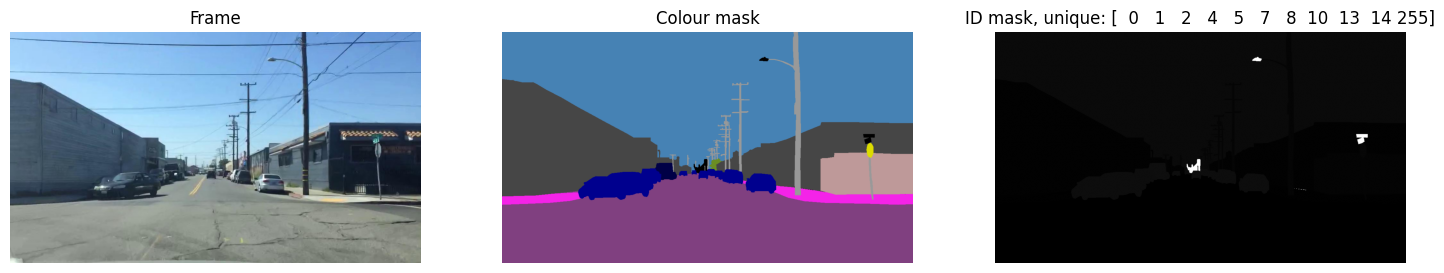

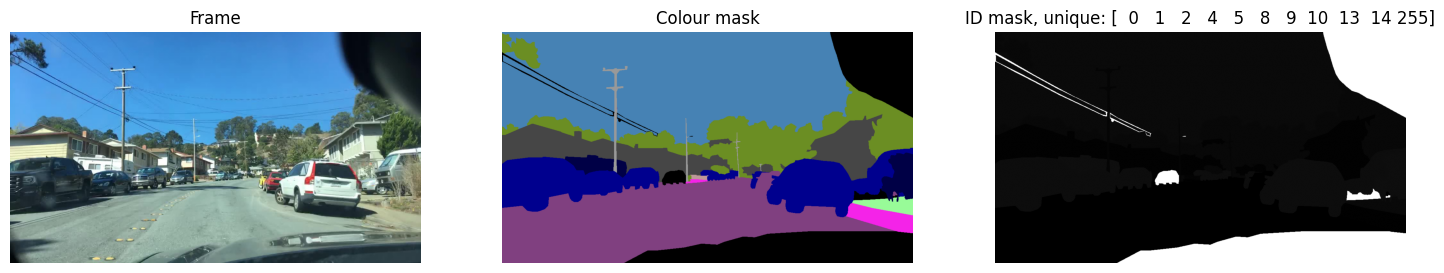

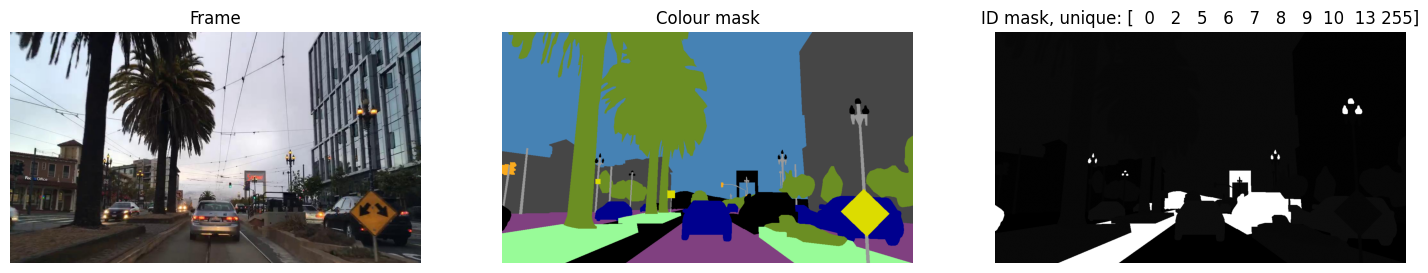

In [ ]:
"""
#step3
#Showing some image mask triplets

def show_sample(idx):
    img_p, col_p, id_p = pairs[idx]
    img = np.array(Image.open(img_p).convert("RGB"))
    col = np.array(Image.open(col_p).convert("RGB"))
    idm = np.array(Image.open(id_p))
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    ax[0].imshow(img);               ax[0].set_title("Frame")
    ax[1].imshow(col);               ax[1].set_title("Colour mask")
    ax[2].imshow(idm, cmap="gray")
    ax[2].set_title(f"ID mask, unique: {np.unique(idm)}")
    for a in ax: a.axis("off")
    plt.show()

for i in random.sample(range(len(pairs)), 3):
    show_sample(i)
    """

In [ ]:
"""
#step4
#Unique IDs and per-class pixel counts

from collections import Counter

N_SAMPLE = min(500, len(pairs))
sample = random.sample(pairs, N_SAMPLE)

pix_count = Counter()
img_presence = Counter()   # number of images in which each ID appears

for _, _, id_p in sample:
    m = np.array(Image.open(id_p))
    vals, cnts = np.unique(m, return_counts=True)
    for v, c in zip(vals, cnts):
        pix_count[int(v)] += int(c)
        img_presence[int(v)] += 1

total = sum(pix_count.values())
print(f"{'ID':>4} | {'% pixels':>9} | {'% images':>9}")
for k in sorted(pix_count):
    print(f"{k:>4} | {100*pix_count[k]/total:9.3f} | {100*img_presence[k]/N_SAMPLE:9.1f}")

# bar plot
ids = sorted(pix_count)
plt.figure(figsize=(10, 4))
plt.bar([str(i) for i in ids], [100*pix_count[i]/total for i in ids])
plt.yscale("log"); plt.xlabel("Class ID"); plt.ylabel("% of pixels (log)")
plt.title("Raw class distribution (sample)")
plt.show()
"""

KeyboardInterrupt: 

In [ ]:
#step5
#checking the masks wrt colored mask before remaping 19 -> 4
"""
CANDIDATES = {"Road": 0, "Pole": 5, "Terrain(Grass)": 9, "Car": 13}

def dominant_colour(class_id, n_images=30):
    cols = Counter()
    for _, col_p, id_p in random.sample(pairs, min(n_images, len(pairs))):
        idm = np.array(Image.open(id_p))
        col = np.array(Image.open(col_p).convert("RGB"))
        sel = col[idm == class_id]
        if len(sel):
            sel = sel[::max(1, len(sel)//2000)]          # subsample pixels
            cols.update(map(tuple, sel.tolist()))
    return cols.most_common(2)

for name, cid in CANDIDATES.items():
    print(f"{name} (ID {cid}): {dominant_colour(cid)}")
    """

Road (ID 0): [((128, 64, 128), 58536)]
Pole (ID 5): [((153, 153, 153), 58082)]


KeyboardInterrupt: 

In [5]:
#step6
#Remapping the labels
from collections import Counter
CLASS_NAMES = ["Background", "Car", "Road", "Grass", "Pole"]
IGNORE = 255

# raw ID -> new ID  (edit after Step 6 is confirmed)
REMAP = {13: 1,   # Car
          0: 2,   # Road
          9: 3,   # Terrain -> Grass
          5: 4}   # Pole

LUT = np.zeros(256, dtype=np.uint8)      # default: background
for raw, new in REMAP.items():
    LUT[raw] = new
LUT[IGNORE] = IGNORE                      # keep ignore label

def remap_mask(id_mask):
    return LUT[id_mask]

# check on a sample
cnt = Counter()
for _, _, id_p in random.sample(pairs, min(200, len(pairs))):
    m = remap_mask(np.array(Image.open(id_p)))
    v, c = np.unique(m, return_counts=True)
    cnt.update(dict(zip(v.tolist(), c.tolist())))

tot = sum(cnt.values())
for k in sorted(cnt):
    name = CLASS_NAMES[k] if k < len(CLASS_NAMES) else "Ignore(255)"
    print(f"{k:>3} {name:<12} {100*cnt[k]/tot:7.3f} %")

  0 Background    51.855 %
  1 Car            9.054 %
  2 Road          19.867 %
  3 Grass          1.037 %
  4 Pole           0.806 %
255 Ignore(255)   17.381 %


In [7]:
#Step 10b: cut-paste Pole augmentation (functions)
import cv2
CP_DIR = "/content/cp_data"; os.makedirs(CP_DIR, exist_ok=True)
N_CP = 20                                  # number of synthetic frames inside the 320
POLE, CAR, ROAD, TERR = 5, 13, 0, 9       # raw IDs (Step 6)
HZ = 0.45                                 # approximate horizon, fraction of image height
CP_LOG = {}

def read_pair(s):
    return np.array(Image.open(img_map[s]).convert("RGB")), np.array(Image.open(id_map[s]))

def build_pole_bank(donor_names, max_imgs=150, min_h=50, min_ar=2.5):
    bank = []
    for s in donor_names[:max_imgs]:
        img, idm = read_pair(s)
        Hh, Ww = idm.shape
        n, lab, st, _ = cv2.connectedComponentsWithStats((idm == POLE).astype(np.uint8), connectivity=8)
        for i in range(1, n):
            x, y, w, h, a = [int(v) for v in st[i]]
            if h < min_h or h / max(w, 1) < min_ar or a < 150: continue   # tall, thin, large enough
            if y == 0 or x == 0 or x + w >= Ww: continue                  # not cut by the image border
            if (y + h) / Hh < 0.55: continue                              # base low enough for scaling
            bank.append(dict(src=s, box=(x, y, w, h), rgb=img[y:y+h, x:x+w].copy(),
                             mask=(lab[y:y+h, x:x+w] == i).astype(np.uint8),
                             ybot=(y + h) / Hh, H=Hh))
    return bank

def paste_poles(base_img, base_id, bank, rng, n_poles=3):
    img = base_img.astype(np.float32).copy(); idm = base_id.copy()
    Hb, Wb = idm.shape
    ground = np.argwhere(((idm == ROAD) | (idm == TERR)) & (np.arange(Hb)[:, None] > 0.55 * Hb))
    if len(ground) == 0: return None
    used = []
    for _ in range(n_poles):
        for _try in range(30):
            p = bank[rng.randrange(len(bank))]
            yb, xb = ground[rng.randrange(len(ground))]                   # foot of the pole
            s = ((yb / Hb) - HZ) / (p["ybot"] - HZ) * (Hb / p["H"])       # perspective scale
            s = float(np.clip(s * rng.uniform(0.85, 1.15), 0.3, 2.0))
            ph, pw = p["mask"].shape
            nh, nw = max(int(ph * s), 8), max(int(pw * s), 2)
            rgb = cv2.resize(p["rgb"], (nw, nh), interpolation=cv2.INTER_AREA)
            m = cv2.resize(p["mask"], (nw, nh), interpolation=cv2.INTER_NEAREST)
            y0, x0 = int(yb) - nh + 1, int(xb) - nw // 2
            if y0 < 0 or x0 < 0 or x0 + nw > Wb or m.sum() < 20: continue
            break
        else:
            continue
        region = idm[y0:y0+nh, x0:x0+nw]                                  # view of the mask
        pm = (m > 0) & (region != CAR) & (region != 255)                  # never cover Car
        alpha = cv2.GaussianBlur(pm.astype(np.float32), (3, 3), 0.8)[..., None]
        img[y0:y0+nh, x0:x0+nw] = alpha * rgb + (1 - alpha) * img[y0:y0+nh, x0:x0+nw]
        region[pm] = POLE                                                 # label = Pole (raw ID 5)
        used.append(dict(box=(x0, y0, nw, nh), rgb=rgb, mask=pm, src=p["src"], src_box=p["box"]))
    if not used: return None
    return np.clip(img, 0, 255).astype(np.uint8), idm, used

def make_cutpaste_subset(subset, all_names, n_cp=N_CP, seed=SEED):
    rng = random.Random(seed)
    outside = [s for s in all_names if s not in set(subset)]             # donors never inside the 320
    rng.shuffle(outside)
    bank = build_pole_bank(outside)
    print("Pole bank:", len(bank), "patches from", len({p["src"] for p in bank}), "frames")
    assert len(bank) > 0, "No usable poles found: relax min_h / min_ar"
    CP_LOG.clear(); replaced = []
    for b in rng.sample(subset, len(subset)):
        if len(replaced) == n_cp: break
        img, idm = read_pair(b)
        out = paste_poles(img, idm, bank, rng, n_poles=rng.randint(2, 4))
        if out is None: continue
        s_img, s_id, used = out
        name = f"{b}_cp"
        Image.fromarray(s_img).save(f"{CP_DIR}/{name}.png")
        Image.fromarray(s_id).save(f"{CP_DIR}/{name}_id.png")
        img_map[name] = f"{CP_DIR}/{name}.png"; id_map[name] = f"{CP_DIR}/{name}_id.png"
        CP_LOG[name] = dict(base=b, base_img=img, base_id=idm, syn_img=s_img, syn_id=s_id, used=used)
        replaced.append(b)
    new = [s for s in subset if s not in replaced] + list(CP_LOG)
    assert len(new) == len(subset)
    return sorted(new)

In [ ]:
#step7
#visually checking if the remap went correctly
"""
PALETTE = np.array([[0,0,0],[0,0,255],[128,64,128],[0,255,0],[255,255,0]], dtype=np.uint8)

def show_remap(idx):
    img_p, _, id_p = pairs[idx]
    img = np.array(Image.open(img_p).convert("RGB"))
    raw = np.array(Image.open(id_p))
    m = remap_mask(raw)

    vis = PALETTE[np.where(m == IGNORE, 0, m)].copy()    # classes 0-4 -> colours
    vis[m == IGNORE] = (128, 128, 128)                   # 255 (ignore) shown in gray

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].imshow(img);                         ax[0].set_title("Frame")
    ax[1].imshow(raw, cmap="gray"); ax[1].set_title("ID mask (19 classes)")
    ax[2].imshow(vis);                         ax[2].set_title("Remapped: Car blue, Road purple, Grass green, Pole yellow, ignore gray", fontsize=9)
    for a in ax: a.axis("off")
    plt.show()

for i in random.sample(range(len(pairs)), 3):
    show_remap(i)
    """

'\nPALETTE = np.array([[0,0,0],[0,0,255],[128,64,128],[0,255,0],[255,255,0]], dtype=np.uint8)\n\ndef show_remap(idx):\n    img_p, _, id_p = pairs[idx]\n    img = np.array(Image.open(img_p).convert("RGB"))\n    raw = np.array(Image.open(id_p))\n    m = remap_mask(raw)\n\n    vis = PALETTE[np.where(m == IGNORE, 0, m)].copy()    # classes 0-4 -> colours\n    vis[m == IGNORE] = (128, 128, 128)                   # 255 (ignore) shown in gray\n\n    fig, ax = plt.subplots(1, 3, figsize=(15, 4))\n    ax[0].imshow(img);                         ax[0].set_title("Frame")\n    ax[1].imshow(raw, cmap="gray"); ax[1].set_title("ID mask (19 classes)")\n    ax[2].imshow(vis);                         ax[2].set_title("Remapped: Car blue, Road purple, Grass green, Pole yellow, ignore gray", fontsize=9)\n    for a in ax: a.axis("off")\n    plt.show()\n\nfor i in random.sample(range(len(pairs)), 3):\n    show_remap(i)\n    '

In [7]:
# Step 9: Estimate class weights with progress and timing

import time
import random
import numpy as np
from PIL import Image

N_W = min(500, len(pairs))  # Start with 500 masks
sampled_pairs = random.sample(pairs, N_W)

cnt = np.zeros(5, dtype=np.int64)
start = time.time()

for i, (_, _, id_p) in enumerate(sampled_pairs, start=1):
    with Image.open(id_p) as im:
        m = remap_mask(np.array(im))

    valid = m[m != IGNORE]
    cnt += np.bincount(valid.ravel(), minlength=5)[:5]

    if i % 50 == 0 or i == N_W:
        elapsed = time.time() - start
        print(f"Processed {i}/{N_W} masks | {elapsed:.1f}s elapsed")

if cnt.sum() == 0:
    raise ValueError("No valid pixels found in the sampled masks.")

freq = cnt / cnt.sum()
w = 1.0 / (freq + 1e-9)
class_weights = w / w.mean()

for name, f in zip(CLASS_NAMES, freq):
    print(f"{name:<11} {100*f:7.3f}%")

print("Class weights:", np.round(class_weights, 3))
print(f"Total time: {time.time() - start:.1f}s")

np.save(os.path.join(OUT_DIR, "class_weights.npy"), class_weights)


Processed 50/500 masks | 16.8s elapsed
Processed 100/500 masks | 30.2s elapsed
Processed 150/500 masks | 44.7s elapsed
Processed 200/500 masks | 59.2s elapsed
Processed 250/500 masks | 73.5s elapsed
Processed 300/500 masks | 90.3s elapsed
Processed 350/500 masks | 105.2s elapsed
Processed 400/500 masks | 120.0s elapsed
Processed 450/500 masks | 134.4s elapsed
Processed 500/500 masks | 147.9s elapsed
Background   63.023%
Car          10.068%
Road         25.069%
Grass         0.831%
Pole          1.009%
Class weights: [0.034 0.211 0.085 2.56  2.11 ]
Total time: 147.9s


In [8]:
#Step 11: random 320-image subset, then 5-fold split
from sklearn.model_selection import KFold, train_test_split

N_SUBSET = 320
names   = sorted(common)
SUBSET2 = sorted(random.Random(SEED).sample(names, N_SUBSET))
SUBSET2 = make_cutpaste_subset(SUBSET2, names)      # <-- added: 6 frames become cut-paste Pole frames
print("Synthetic frames:", list(CP_LOG))     # 4% of the data, fixed seed


kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
folds = {}
for k, (trainval_idx, test_idx) in enumerate(kf.split(SUBSET2)):
    trainval = [SUBSET2[i] for i in trainval_idx]
    test     = [SUBSET2[i] for i in test_idx]
    train, val = train_test_split(trainval, test_size=0.25, random_state=SEED)
    assert not (set(train) & set(val)) and not (set(train) & set(test)) and not (set(val) & set(test))
    folds[k] = {"train": train, "val": val, "test": test}
    print(f"Fold {k}: train {len(train)} | val {len(val)} | test {len(test)}")

assert sorted(n for k in folds for n in folds[k]["test"]) == SUBSET2

Pole bank: 230 patches from 83 frames
Synthetic frames: ['04f64fe8-00000000_cp', '3a570e80-61d29766_cp', '2dc4e4d2-e119b0cf_cp', '00e9be89-00001820_cp', '00e9be89-00001900_cp', '1dbc80db-797460c9_cp', '4a592fc2-1f10618d_cp', '0be36567-bee11e9c_cp', '00e9be89-00001670_cp', '0ac3cbf4-a764bdbc_cp', '1b42cfb0-231ac07e_cp', '3ec64125-972fa4e9_cp', '3d50b2fd-031cce4f_cp', '1e15cae7-5d932386_cp', '2afddd2b-f636e99f_cp', '3c469980-fb0ca2f9_cp', '1c2a60fd-87d1bf52_cp', '2eb0f2a5-a5690001_cp', '3af8c849-e491ddbb_cp', '2cf343a9-c2028048_cp']
Fold 0: train 192 | val 64 | test 64
Fold 1: train 192 | val 64 | test 64
Fold 2: train 192 | val 64 | test 64
Fold 3: train 192 | val 64 | test 64
Fold 4: train 192 | val 64 | test 64


In [10]:
#step 12
import keras
import numpy as np, random
from PIL import Image

H, W = 256, 448

class SegSequence(keras.utils.PyDataset):
    def __init__(self, names, batch_size=16, train=False, **kwargs):
        super().__init__(**kwargs)
        self.names, self.batch_size, self.train = list(names), batch_size, train

    def __len__(self):
        return int(np.ceil(len(self.names) / self.batch_size))

    def on_epoch_end(self):
        if self.train:
            random.shuffle(self.names)

    def __getitem__(self, idx):
        batch = self.names[idx * self.batch_size:(idx + 1) * self.batch_size]
        X = np.zeros((len(batch), H, W, 3), np.float32)
        Y = np.zeros((len(batch), H, W), np.int32)
        for j, s in enumerate(batch):
            img = Image.open(img_map[s]).convert("RGB").resize((W, H), Image.BILINEAR)
            img = np.asarray(img, np.float32) / 255.0
            m = remap_mask(np.array(Image.open(id_map[s])))
            msk = np.asarray(Image.fromarray(m).resize((W, H), Image.NEAREST), np.int32)
            if self.train:
                if random.random() < 0.5:
                    img, msk = img[:, ::-1], msk[:, ::-1]
                img = np.clip(img * random.uniform(0.8, 1.2), 0, 1)
            X[j], Y[j] = img, msk
        return X, Y

def get_loaders(fold, batch_size=16, workers=4):
    f = folds[fold]
    return (SegSequence(f["train"], batch_size, True,  workers=workers),
            SegSequence(f["val"],   batch_size, False, workers=workers),
            SegSequence(f["test"],  batch_size, False, workers=workers))

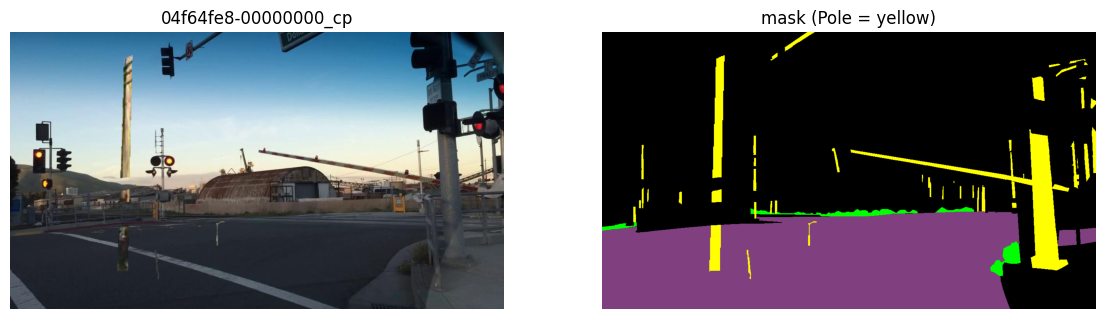

In [11]:
s = list(CP_LOG)[0]
PAL = np.array([[0,0,0],[0,0,255],[128,64,128],[0,255,0],[255,255,0]], np.uint8)  # Bg, Car, Road, Grass, Pole
def colour(idm): return PAL[np.where(idm == 255, 0, remap_mask(idm))]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(Image.open(img_map[s]));                        ax[0].set_title(s)
ax[1].imshow(colour(np.array(Image.open(id_map[s]))));       ax[1].set_title("mask (Pole = yellow)")
for a in ax: a.axis("off")
plt.show()

In [12]:
#step 13
#FCN
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose
from keras.optimizers import Adam

def conv2d(x, filters, conv_layers=1):
    for _ in range(conv_layers):
        x = Conv2D(filters, 3, padding="same", activation="relu")(x)
    return x

def deconv2d(x, filters):
    return Conv2DTranspose(filters, 2, strides=2, padding="same", activation="relu")(x)

def build_fcn(filters=8, n_classes=5, height=H, width=W, input_channels=3,
              conv_layers=1, depth=4):
    inputs = Input(shape=(height, width, input_channels))
    x = inputs
    for d in range(depth):                                   # encoder
        x = conv2d(x, filters * 2**d, conv_layers)
        x = MaxPooling2D(2)(x)
    x = conv2d(x, filters * 2**depth, conv_layers)           # bottleneck
    for d in reversed(range(depth)):                         # decoder (no skips)
        x = deconv2d(x, filters * 2**d)
        x = conv2d(x, filters * 2**d, conv_layers)
    outputs = Conv2D(n_classes, 1, activation="softmax")(x)  # 5 class probabilities per pixel
    return Model(inputs, outputs, name="FCN")

def compile_model(model, lr=1e-4):
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss=keras.losses.SparseCategoricalCrossentropy(ignore_class=255),
                  metrics=["accuracy"])
    return model

# check
fcn = compile_model(build_fcn())
fcn.summary()
tr, va, te = get_loaders(0)
x, y = tr[0]
p = fcn.predict(x[:2], verbose=0)
print(x.shape, y.shape, p.shape)    # expected (16,256,448,3) (16,256,448) (2,256,448,5)

Model: "FCN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 448, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 448, 8)    │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 224, 8)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 224, 16)   │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 112, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 112, 32)    │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 32, 56, 64)     │        32,832 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 56, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 64, 112, 32)    │         8,224 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 112, 32)    │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 128, 224, 16)   │         2,064 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 128, 224, 16)   │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 256, 448, 8)    │           520 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 256, 448, 8)    │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 256, 448, 5)    │            45 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 191,149 (746.68 KB)

 Trainable params: 191,149 (746.68 KB)

 Non-trainable params: 0 (0.00 B)

(16, 256, 448, 3) (16, 256, 448) (2, 256, 448, 5)


In [13]:
#step 14
#UNet model
from keras.layers import Concatenate

def build_unet(filters=8, n_classes=5, height=H, width=W, input_channels=3,
               conv_layers=1, depth=4):
    inputs = Input(shape=(height, width, input_channels))
    x, skips = inputs, []
    for d in range(depth):                                   # encoder
        x = conv2d(x, filters * 2**d, conv_layers)
        skips.append(x)                                      # saved for the decoder
        x = MaxPooling2D(2)(x)
    x = conv2d(x, filters * 2**depth, conv_layers)           # bottleneck
    for d in reversed(range(depth)):                         # decoder
        x = deconv2d(x, filters * 2**d)
        x = Concatenate()([x, skips[d]])                     # skip connection
        x = conv2d(x, filters * 2**d, conv_layers)
    outputs = Conv2D(n_classes, 1, activation="softmax")(x)
    return Model(inputs, outputs, name="UNet")

unet = compile_model(build_unet())
unet.summary()
print("Output shape:", unet.output_shape)    # expected (None, 256, 448, 5)

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 448,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 256, 448,  │        224 │ input_layer_1[0]… │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 224,  │          0 │ conv2d_10[0][0]   │
│ (MaxPooling2D)      │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 128, 224,  │      1,168 │ max_pooling2d_4[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 112,   │          0 │ conv2d_11[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 112,   │      4,640 │ max_pooling2d_5[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 32, 56,    │          0 │ conv2d_12[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 32, 56,    │     18,496 │ max_pooling2d_6[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 16, 28,    │          0 │ conv2d_13[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 16, 28,    │     73,856 │ max_pooling2d_7[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_4  │ (None, 32, 56,    │     32,832 │ conv2d_14[0][0]   │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 56,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 128)              │            │ conv2d_13[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 32, 56,    │     73,792 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_5  │ (None, 64, 112,   │      8,224 │ conv2d_15[0][0]   │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64, 112,   │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 64)               │            │ conv2d_12[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 64, 112,   │     18,464 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_6  │ (None, 128, 224,  │      2,064 │ conv2d_16[0][0] 

 Total params: 240,109 (937.93 KB)

 Trainable params: 240,109 (937.93 KB)

 Non-trainable params: 0 (0.00 B)

Output shape: (None, 256, 448, 5)


In [14]:
#Step 15
#Attention UNet
from keras.layers import BatchNormalization, Activation, Add, Multiply

def attention_block(g, skip, f_int):
    g_  = BatchNormalization()(Conv2D(f_int, 1, padding="same")(g))      # gating signal (decoder)
    x_  = BatchNormalization()(Conv2D(f_int, 1, padding="same")(skip))   # skip features (encoder)
    psi = Activation("relu")(Add()([g_, x_]))
    psi = Activation("sigmoid")(Conv2D(1, 1, padding="same")(psi))       # attention map, values 0 to 1
    return Multiply()([skip, psi])                                       # suppresses irrelevant regions

def build_attention_unet(filters=8, n_classes=5, height=H, width=W, input_channels=3,
                         conv_layers=1, depth=4):
    inputs = Input(shape=(height, width, input_channels))
    x, skips = inputs, []
    for d in range(depth):                                   # encoder
        x = conv2d(x, filters * 2**d, conv_layers)
        skips.append(x)
        x = MaxPooling2D(2)(x)
    x = conv2d(x, filters * 2**depth, conv_layers)           # bottleneck
    for d in reversed(range(depth)):                         # decoder
        x = deconv2d(x, filters * 2**d)
        att = attention_block(x, skips[d], filters * 2**d)   # gate the skip using the decoder signal
        x = Concatenate()([x, att])
        x = conv2d(x, filters * 2**d, conv_layers)
    outputs = Conv2D(n_classes, 1, activation="softmax")(x)
    return Model(inputs, outputs, name="AttentionUNet")

att_unet = compile_model(build_attention_unet())
att_unet.summary()
print("Output shape:", att_unet.output_shape)    # expected (None, 256, 448, 5)

Model: "AttentionUNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 448,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 448,  │        224 │ input_layer_2[0]… │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 128, 224,  │          0 │ conv2d_20[0][0]   │
│ (MaxPooling2D)      │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 224,  │      1,168 │ max_pooling2d_8[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 64, 112,   │          0 │ conv2d_21[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 64, 112,   │      4,640 │ max_pooling2d_9[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 32, 56,    │          0 │ conv2d_22[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 32, 56,    │     18,496 │ max_pooling2d_10… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 16, 28,    │          0 │ conv2d_23[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 16, 28,    │     73,856 │ max_pooling2d_11… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_8  │ (None, 32, 56,    │     32,832 │ conv2d_24[0][0]   │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 56,    │      4,160 │ conv2d_transpose… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 32, 56,    │      4,160 │ conv2d_23[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 56,    │        256 │ conv2d_25[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 56,    │        256 │ conv2d_26[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 56,    │          0 │ add[0][0]       

 Total params: 252,313 (985.60 KB)

 Trainable params: 251,833 (983.72 KB)

 Non-trainable params: 480 (1.88 KB)

Output shape: (None, 256, 448, 5)


In [ ]:
"""
#Step 16
#YOLO data prepation
import cv2, shutil
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

YOLO_DIR = "/content/yolo"
os.makedirs(f"{YOLO_DIR}/images/all", exist_ok=True)
os.makedirs(f"{YOLO_DIR}/labels/all", exist_ok=True)

MIN_AREA = 30    # drop regions smaller than 30 pixels

def mask_to_yolo_lines(m):
    h, w = m.shape
    lines = []
    for new_id in (1, 2, 3, 4):                               # Car, Road, Grass, Pole
        binm = (m == new_id).astype(np.uint8)
        if not binm.any():
            continue
        cnts, _ = cv2.findContours(binm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            if len(c) < 3 or cv2.contourArea(c) < MIN_AREA:
                continue
            c = cv2.approxPolyDP(c, 1.0, True)
            if len(c) < 3:
                continue
            pts = c.reshape(-1, 2).astype(np.float32)
            pts[:, 0] /= w; pts[:, 1] /= h
            lines.append(f"{new_id - 1} " + " ".join(f"{v:.5f}" for v in pts.ravel()))
    return lines

yolo_img_path = {}

def build_one(s):
    src = img_map[s]
    dst = f"{YOLO_DIR}/images/all/{s}{os.path.splitext(src)[1]}"
    if not os.path.exists(dst):
        os.symlink(src, dst)
    m = remap_mask(np.array(Image.open(id_map[s])))
    m = np.where(m == IGNORE, 0, m).astype(np.uint8)          # unlabeled treated as background
    with open(f"{YOLO_DIR}/labels/all/{s}.txt", "w") as f:
        f.write("\n".join(mask_to_yolo_lines(m)))
    return s, dst

with ThreadPoolExecutor(max_workers=8) as ex:
    for s, dst in tqdm(ex.map(build_one, common), total=len(common)):
        yolo_img_path[s] = dst

def write_fold_yaml(k):
    for split in ("train", "val", "test"):
        with open(f"{YOLO_DIR}/fold{k}_{split}.txt", "w") as fh:
            fh.write("\n".join(yolo_img_path[s] for s in folds[k][split]))
    yp = f"{YOLO_DIR}/fold{k}.yaml"
    with open(yp, "w") as fh:
        fh.write(f"path: {YOLO_DIR}\n"
                 f"train: {YOLO_DIR}/fold{k}_train.txt\n"
                 f"val: {YOLO_DIR}/fold{k}_val.txt\n"
                 f"test: {YOLO_DIR}/fold{k}_test.txt\n"
                 "names:\n  0: Car\n  1: Road\n  2: Grass\n  3: Pole\n")
    return yp
    """

100%|██████████| 1759/1759 [00:18<00:00, 94.25it/s] 


In [9]:
#Step 17
#Shared metrics (all four models)
import pandas as pd

def confusion(gt, pred, n=5):
    valid = gt != IGNORE
    return np.bincount(n * gt[valid].astype(np.int64) + pred[valid].astype(np.int64),
                       minlength=n * n).reshape(n, n)

def metrics_from_conf(conf, model_name, fold):
    tp = np.diag(conf); fp = conf.sum(0) - tp; fn = conf.sum(1) - tp
    acc = tp.sum() / conf.sum()
    return [dict(fold=fold, model=model_name, cls=CLASS_NAMES[c],
                 TP=int(tp[c]), FP=int(fp[c]), FN=int(fn[c]),
                 dice=2*tp[c] / (2*tp[c] + fp[c] + fn[c] + 1e-9),
                 iou=tp[c] / (tp[c] + fp[c] + fn[c] + 1e-9),
                 precision=tp[c] / (tp[c] + fp[c] + 1e-9),
                 recall=tp[c] / (tp[c] + fn[c] + 1e-9),
                 accuracy=acc) for c in range(5)]

def evaluate_keras(model, loader):
    conf = np.zeros((5, 5), np.int64)
    for i in range(len(loader)):
        x, y = loader[i]
        xf = np.ascontiguousarray(x[:, :, ::-1])
        p = model.predict(x, verbose=0) + model.predict(xf, verbose=0)[:, :, ::-1]
        conf += confusion(y, np.argmax(p, axis=-1))
    return conf

In [16]:
#Step 18: cache, loader, loss and 5-fold training of FCN, U-Net and Attention U-Net (GPU settings)
import time
from functools import partial
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from keras.layers import Conv2D, BatchNormalization, Activation
import gc

# ---------------- settings ----------------
RESULTS_CSV = "/content/drive/MyDrive/seg_results_full.csv"
MODEL_DIR   = "/content/drive/MyDrive/seg_models"
os.makedirs(MODEL_DIR, exist_ok=True)

FILTERS      = 8
EPOCHS       = 20
LR           = 1e-3
BATCH_SIZE   = 8
FOLDS_TO_RUN = 5        # 1 = test on fold 0 first; set to 5 for the full run (finished pairs are skipped)
RESET_KERAS  = True     # True: drop old FCN/UNet/AttentionUNet rows once (YOLO rows are kept).
                        # Set to False when resuming after a disconnect, otherwise progress is erased.

assert "SUBSET2" in globals() and len(folds[0]["train"]) < 300, "Run Step 11 and both nested-fold cells first"

# ---------------- results file ----------------
if os.path.exists(RESULTS_CSV):
    old = pd.read_csv(RESULTS_CSV)
    if RESET_KERAS:
        old = old[old.model == "YOLOv8-seg"]
        old.to_csv(RESULTS_CSV, index=False)
    results = old.to_dict("records")
else:
    results = []
done = {(r["fold"], r["model"]) for r in results}

# ---------------- convolution block with BatchNorm (replaces the earlier conv2d; used by all 3 models) ----------------
def conv2d(x, filters, conv_layers=1):
    for _ in range(conv_layers):
        x = Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = BatchNormalization()(x)
        x = Activation("relu")(x)
    return x

# ---------------- RAM cache of resized data (nothing saved to Drive) ----------------
def load_pair(s):
    img = Image.open(img_map[s]).convert("RGB").resize((W, H), Image.BILINEAR)
    m = remap_mask(np.array(Image.open(id_map[s])))
    msk = Image.fromarray(m).resize((W, H), Image.NEAREST)
    return np.asarray(img, np.uint8), np.asarray(msk, np.uint8)

need_rebuild = ("IMG_CACHE" not in globals()
                or next(iter(IMG_CACHE.values())).shape[:2] != (H, W)
                or not all(s in IMG_CACHE for s in SUBSET2))
if need_rebuild:
    all_names = SUBSET2
    with ThreadPoolExecutor(max_workers=16) as ex:
        out = list(tqdm(ex.map(load_pair, all_names), total=len(all_names)))
    IMG_CACHE = {s: o[0] for s, o in zip(all_names, out)}
    MSK_CACHE = {s: o[1] for s, o in zip(all_names, out)}
    del out

# ---------------- data loader reading from the cache ----------------
class SegSequence(keras.utils.PyDataset):
    def __init__(self, names, batch_size=16, train=False, **kwargs):
        super().__init__(**kwargs)
        self.names, self.batch_size, self.train = list(names), batch_size, train

    def __len__(self):
        return int(np.ceil(len(self.names) / self.batch_size))

    def on_epoch_end(self):
        if self.train:
            random.shuffle(self.names)

    def __getitem__(self, idx):
        batch = self.names[idx * self.batch_size:(idx + 1) * self.batch_size]
        X = np.zeros((len(batch), H, W, 3), np.float32)
        Y = np.zeros((len(batch), H, W), np.int32)
        for j, s in enumerate(batch):
            img = IMG_CACHE[s].astype(np.float32) / 255.0
            msk = MSK_CACHE[s]
            if self.train:
                if random.random() < 0.5:
                    img, msk = img[:, ::-1], msk[:, ::-1]
                img = np.clip(img * random.uniform(0.8, 1.2), 0, 1)
            X[j], Y[j] = img, msk
        return X, Y

POLE_IMGS = {s for s in SUBSET2 if (MSK_CACHE[s] == 4).sum() > 30}
def get_loaders(fold, batch_size=BATCH_SIZE):
  f = folds[fold]
  tr_names = f["train"] + [s for s in f["train"] if s in POLE_IMGS]
  return (SegSequence(tr_names, batch_size, True), SegSequence(f["val"], batch_size, False), SegSequence(f["test"], batch_size, False))

# ---------------- loss: weighted cross-entropy + Dice (foreground classes) ----------------
def make_ce_dice_loss(weights, ignore=255, n=5, dice_w=1.0):
    w = keras.ops.convert_to_tensor(weights, dtype="float32")
    def loss(y_true, y_pred):
        y_true = keras.ops.cast(y_true, "int32")
        valid  = keras.ops.cast(y_true != ignore, "float32")
        y_safe = keras.ops.where(y_true == ignore, 0, y_true)
        ce = keras.losses.sparse_categorical_crossentropy(y_safe, y_pred)
        wt = keras.ops.take(w, y_safe) * valid
        ce = keras.ops.sum(ce * wt) / (keras.ops.sum(wt) + 1e-7)
        oh = keras.ops.one_hot(y_safe, n) * valid[..., None]
        p  = y_pred * valid[..., None]
        inter = keras.ops.sum(oh * p, axis=(0, 1, 2))
        den   = keras.ops.sum(oh, axis=(0, 1, 2)) + keras.ops.sum(p, axis=(0, 1, 2))
        dice  = 1 - (2 * inter + 1) / (den + 1)
        return ce + dice_w * keras.ops.mean(dice[1:])           # Car, Road, Grass, Pole
    return loss

cw = np.array(class_weights) ** 0.5      # Step 9 class weights, softened (fixed prior)
cw = np.minimum(cw / cw.mean(), 4.0)
LOSS = make_ce_dice_loss(cw)

# ---------------- 5-fold training ----------------
BUILDERS = {"FCN":           partial(build_fcn,            filters=FILTERS, height=H, width=W),
            "UNet":          partial(build_unet,           filters=FILTERS, height=H, width=W),
            "AttentionUNet": partial(build_attention_unet, filters=FILTERS, height=H, width=W)}

for k in range(FOLDS_TO_RUN):
    tr, va, te = get_loaders(k)
    print(f"Fold {k}: train {len(tr.names)} | val {len(va.names)} | test {len(te.names)}")
    for name, builder in BUILDERS.items():
        if (k, name) in done:
            print(f"fold {k} {name} already done, skipped"); continue
        t0 = time.time()
        keras.utils.set_random_seed(SEED)
        model = builder()
        steps = len(tr)
        sched = keras.optimizers.schedules.CosineDecay(1e-5, (EPOCHS - 1) * steps, alpha=0.01,
                                                  warmup_target=1e-3, warmup_steps=steps)
        model.compile(optimizer=Adam(learning_rate=sched), loss=LOSS)
        model.fit(tr, validation_data=va, epochs=EPOCHS, verbose=2,
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=12,
                                                           restore_best_weights=True)])
        results += metrics_from_conf(evaluate_keras(model, te), name, k)
        pd.DataFrame(results).to_csv(RESULTS_CSV, index=False)
        if k == 0:
            model.save(f"{MODEL_DIR}/{name}_fold0.keras")
        keras.backend.clear_session()
        del model; gc.collect(); torch.cuda.empty_cache()
        print(f"fold {k} {name} done in {(time.time() - t0) / 60:.1f} min")

r = pd.DataFrame(results)
print(r[r.model != "YOLOv8-seg"].groupby(["model", "cls"])[["dice", "iou"]].mean().round(3))

100%|██████████| 320/320 [00:07<00:00, 40.44it/s]


Fold 0: train 371 | val 64 | test 64
Epoch 1/20
47/47 - 5s - 115ms/step - loss: 2.5884 - val_loss: 2.5045
Epoch 2/20
47/47 - 5s - 106ms/step - loss: 2.4035 - val_loss: 2.4760
Epoch 3/20
47/47 - 5s - 116ms/step - loss: 2.2087 - val_loss: 2.4554
Epoch 4/20
47/47 - 5s - 104ms/step - loss: 1.9274 - val_loss: 2.4399
Epoch 5/20
47/47 - 5s - 110ms/step - loss: 1.7383 - val_loss: 2.2542
Epoch 6/20
47/47 - 5s - 111ms/step - loss: 1.6155 - val_loss: 2.2746
Epoch 7/20
47/47 - 5s - 105ms/step - loss: 1.5323 - val_loss: 1.8423
Epoch 8/20
47/47 - 5s - 114ms/step - loss: 1.4739 - val_loss: 1.6642
Epoch 9/20
47/47 - 5s - 108ms/step - loss: 1.4226 - val_loss: 1.5219
Epoch 10/20
47/47 - 5s - 112ms/step - loss: 1.3916 - val_loss: 1.5924
Epoch 11/20
47/47 - 6s - 118ms/step - loss: 1.3760 - val_loss: 1.4745
Epoch 12/20
47/47 - 5s - 105ms/step - loss: 1.3185 - val_loss: 1.3736
Epoch 13/20
47/47 - 5s - 108ms/step - loss: 1.2959 - val_loss: 1.3342
Epoch 14/20
47/47 - 5s - 114ms/step - loss: 1.2723 - val_loss:

In [17]:
shutil.rmtree("/content/drive/MyDrive/seg_models/yolo_runs", ignore_errors=True)

NameError: name 'shutil' is not defined

In [19]:
#Step 19: YOLO on the same folds (320-image subset)
!pip install -q ultralytics
import shutil, cv2, time
import torch
from ultralytics import YOLO

# ---------------- settings ----------------
IMGSZ       = 448                      # matches the Keras input (128 x 224); must be a multiple of 32
YOLO_EPOCHS = 20
YOLO_BATCH  = 16
DEVICE      = 0 if torch.cuda.is_available() else "cpu"
YOLO_DIR    = "/content/yolo_sub"
MIN_AREA, EPS = 4, 0.5                 # polygon filters, in pixels of the 128 x 224 mask

assert "MSK_CACHE" in globals() and next(iter(MSK_CACHE.values())).shape == (H, W), "Run Step 18 first (needs the cache)"
assert os.path.exists(RESULTS_CSV), "Results file not found: Step 18 must have finished"

# ---------------- polygon labels and local copy of the 320 frames ----------------
shutil.rmtree(YOLO_DIR, ignore_errors=True)
os.makedirs(f"{YOLO_DIR}/images/all"); os.makedirs(f"{YOLO_DIR}/labels/all")

def mask_to_yolo_lines(m):
    h, w = m.shape
    lines = []
    for new_id in (1, 2, 3, 4):                                    # Car, Road, Grass, Pole
        binm = (m == new_id).astype(np.uint8)
        if not binm.any():
            continue
        cnts, _ = cv2.findContours(binm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            if len(c) < 3 or cv2.contourArea(c) < MIN_AREA:
                continue
            c = cv2.approxPolyDP(c, EPS, True)
            if len(c) < 3:
                continue
            pts = c.reshape(-1, 2).astype(np.float32)
            pts[:, 0] /= w; pts[:, 1] /= h
            lines.append(f"{new_id - 1} " + " ".join(f"{v:.5f}" for v in pts.ravel()))
    return lines

yolo_img_path = {}
for s in SUBSET2:
    src = img_map[s]
    dst = f"{YOLO_DIR}/images/all/{s}{os.path.splitext(src)[1]}"
    shutil.copy(src, dst)
    m = np.where(MSK_CACHE[s] == IGNORE, 0, MSK_CACHE[s]).astype(np.uint8)   # unlabeled treated as background
    with open(f"{YOLO_DIR}/labels/all/{s}.txt", "w") as f:
        f.write("\n".join(mask_to_yolo_lines(m)))
    yolo_img_path[s] = dst
print("YOLO files prepared:", len(yolo_img_path))

def write_fold_yaml(k):
    for split in ("train", "val", "test"):
        with open(f"{YOLO_DIR}/fold{k}_{split}.txt", "w") as fh:
            fh.write("\n".join(yolo_img_path[s] for s in folds[k][split]))
    yp = f"{YOLO_DIR}/fold{k}.yaml"
    with open(yp, "w") as fh:
        fh.write(f"path: {YOLO_DIR}\n"
                 f"train: {YOLO_DIR}/fold{k}_train.txt\n"
                 f"val: {YOLO_DIR}/fold{k}_val.txt\n"
                 f"test: {YOLO_DIR}/fold{k}_test.txt\n"
                 "names:\n  0: Car\n  1: Road\n  2: Grass\n  3: Pole\n")
    return yp

# ---------------- train and evaluate ----------------
def train_yolo(k):
    YOLO("yolov8n-seg.pt").train(
        data=write_fold_yaml(k), epochs=YOLO_EPOCHS, imgsz=IMGSZ, batch=YOLO_BATCH, seed=SEED,
        device=DEVICE, workers=2, cache="ram", plots=False, patience=20, optimizer="AdamW", lr0=0.001, cos_lr=True, close_mosaic=10,
        project=f"{OUT_DIR}/yolo_runs", name=f"fold{k}", exist_ok=True, verbose=False)
    return YOLO(f"{OUT_DIR}/yolo_runs/fold{k}/weights/best.pt")

def evaluate_yolo(model, names):
    conf = np.zeros((5, 5), np.int64)
    preds = model.predict([yolo_img_path[s] for s in names], imgsz=IMGSZ, conf=0.05,
                          retina_masks=True, device=DEVICE, stream=True, verbose=False)
    for s, r in zip(names, preds):
        sem = np.zeros(r.orig_shape, np.uint8)                     # semantic map built from instance masks
        if r.masks is not None:
            cls = r.boxes.cls.cpu().numpy().astype(int)
            msk = r.masks.data.cpu().numpy() > 0.5
            for c in (1, 2, 0, 3):                                 # paint Road, Grass, Car, then Pole on top
                for i in np.where(cls == c)[0]:
                    sem[msk[i]] = c + 1
        sem = cv2.resize(sem, (W, H), interpolation=cv2.INTER_NEAREST)
        conf += confusion(MSK_CACHE[s], sem)                       # ground truth from the cache (255 ignored)
    return conf

results = pd.read_csv(RESULTS_CSV).to_dict("records")
results = [r for r in results if r["model"] != "YOLOv8-seg"]   # drop old YOLO rows
pd.DataFrame(results).to_csv(RESULTS_CSV, index=False)
done = set()

for k in range(5):
    if k in done:
        print(f"fold {k} YOLO already done, skipped"); continue
    t0 = time.time()
    best = train_yolo(k)
    results += metrics_from_conf(evaluate_yolo(best, folds[k]["test"]), "YOLOv8-seg", k)
    pd.DataFrame(results).to_csv(RESULTS_CSV, index=False)
    if k == 0:
        os.makedirs(f"{MODEL_DIR}/yolo_runs/fold0/weights", exist_ok=True)
        shutil.copy(f"{OUT_DIR}/yolo_runs/fold0/weights/best.pt", f"{MODEL_DIR}/yolo_runs/fold0/weights/best.pt")
    print(f"fold {k} YOLO done in {(time.time() - t0) / 60:.1f} min")

print(pd.DataFrame(results).query("model == 'YOLOv8-seg'").groupby("cls")[["dice", "iou"]].mean().round(3))

YOLO files prepared: 320
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_sub/fold0.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=448, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fold0, nbs=64, nms=None, opset=Non

model     FCN    UNet  AttentionUNet  YOLOv8-seg
fold                                            
0      0.6166  0.5268         0.5608      0.3532
1      0.6045  0.4997         0.5167      0.3727
2      0.6070  0.4982         0.5251      0.3792
3      0.6086  0.5088         0.5451      0.4155
4      0.6053  0.4916         0.5266      0.4133
mean   0.6084  0.5050         0.5349      0.3868
std    0.0049  0.0136         0.0179      0.0270


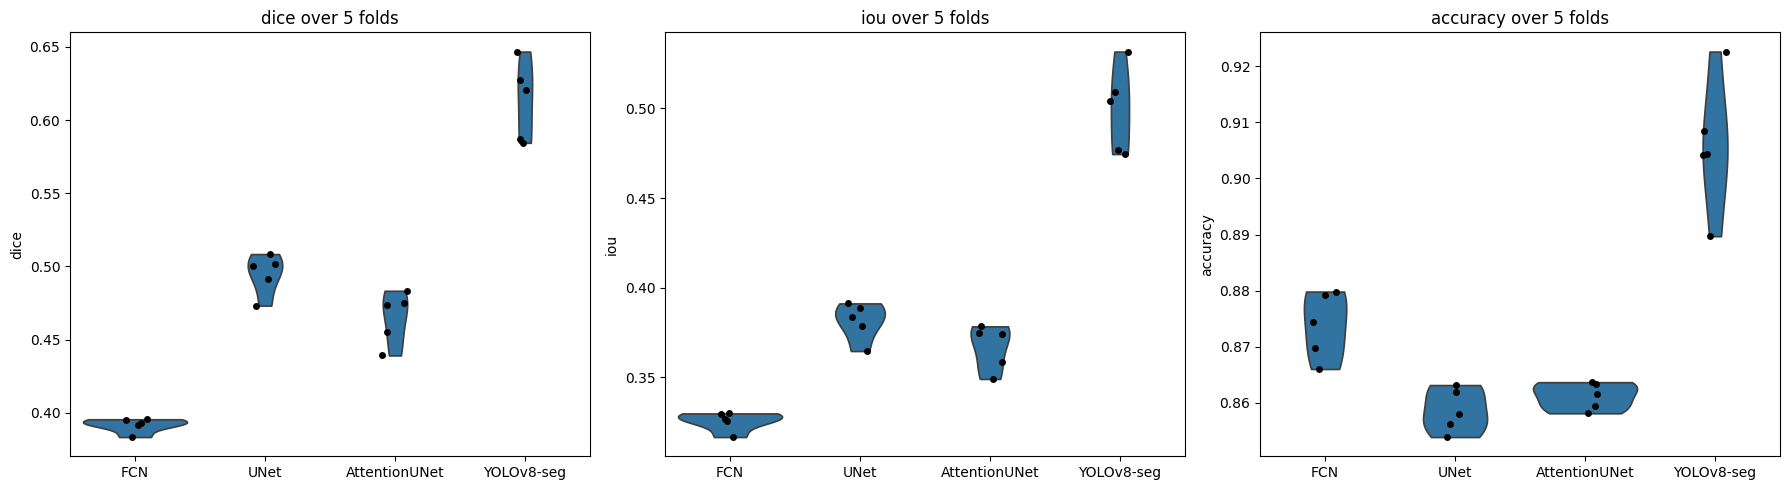

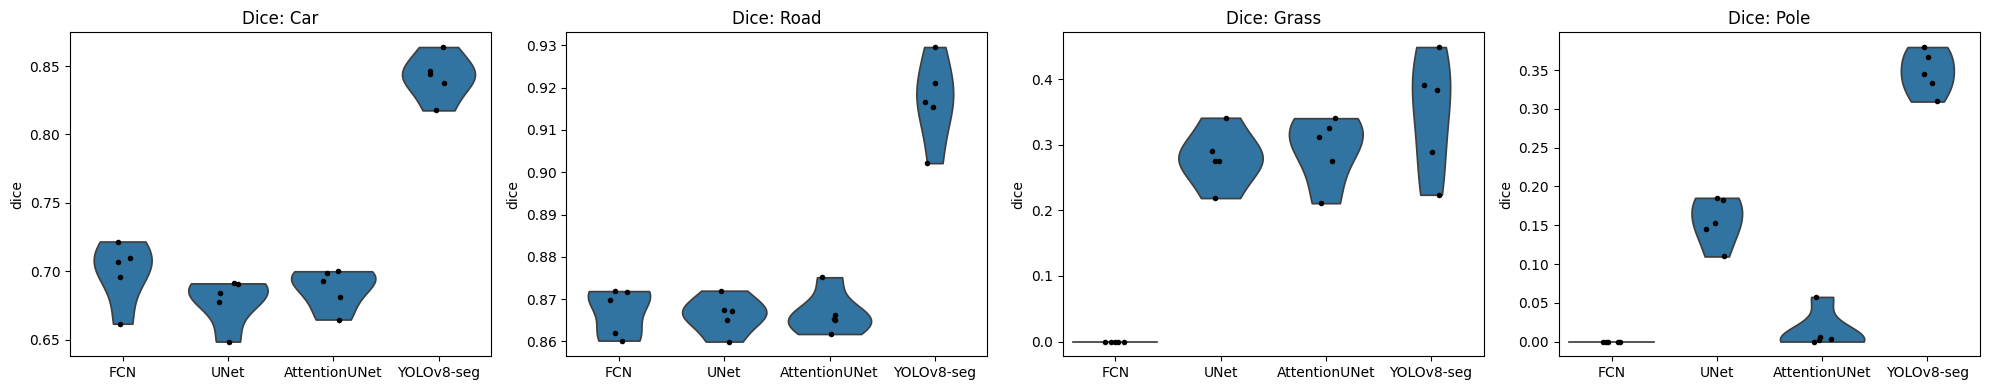

In [20]:
#Step 20
#Error table and violin plots (5 folds)
import pandas as pd, seaborn as sns, itertools
from scipy import stats

df = pd.read_csv(RESULTS_CSV)
FG = ["Car", "Road", "Grass", "Pole"]
ORDER = [m for m in ["FCN", "UNet", "AttentionUNet", "YOLOv8-seg"] if m in df.model.unique()]

fg = df[df.cls.isin(FG)]
per_fold = (fg.groupby(["model", "fold"])
              .agg(dice=("dice", "mean"), iou=("iou", "mean"), accuracy=("accuracy", "first"))
              .reset_index())
per_fold["dice_error"] = 1 - per_fold["dice"]

# error table: rows = folds, columns = models
tab = per_fold.pivot(index="fold", columns="model", values="dice_error")[ORDER]
tab.loc["mean"], tab.loc["std"] = tab.mean(), tab.std()
print(tab.round(4))
tab.round(4).to_csv("/content/drive/MyDrive/seg_error_table.csv")

# violin plots over the 5 folds
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, m in zip(ax, ["dice", "iou", "accuracy"]):
    sns.violinplot(data=per_fold, x="model", y=m, order=ORDER, inner=None, cut=0, ax=a)
    sns.stripplot(data=per_fold, x="model", y=m, order=ORDER, color="k", size=5, ax=a)
    a.set_title(f"{m} over 5 folds"); a.set_xlabel("")
plt.tight_layout(); plt.savefig("/content/drive/MyDrive/violin_overall.png", dpi=150); plt.show()

# per-class Dice
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, c in zip(ax, FG):
    sns.violinplot(data=df[df.cls == c], x="model", y="dice", order=ORDER, inner=None, cut=0, ax=a)
    sns.stripplot(data=df[df.cls == c], x="model", y="dice", order=ORDER, color="k", size=4, ax=a)
    a.set_title(f"Dice: {c}"); a.set_xlabel("")
plt.tight_layout(); plt.savefig("/content/drive/MyDrive/violin_per_class.png", dpi=150); plt.show()

                          TP       FP      FN  FP/FN            tendency
model         cls                                                       
AttentionUNet Car    2409091  1450228  743138   1.95   over-segmentation
              Grass   187683   664577  219090   3.03   over-segmentation
              Pole      1723     2314  298749   0.01  under-segmentation
              Road   6617809  1212109  821013   1.48   over-segmentation
FCN           Car    2335200  1195673  817029   1.46   over-segmentation
              Grass        0        1  406773   0.00  under-segmentation
              Pole         0        0  300472   0.00  under-segmentation
              Road   6774425  1411476  664397   2.12   over-segmentation
UNet          Car    2379105  1483125  773124   1.92   over-segmentation
              Grass   168686   623559  238087   2.62   over-segmentation
              Pole     36061   135484  264411   0.51  under-segmentation
              Road   6640201  1249890  798621   1.5

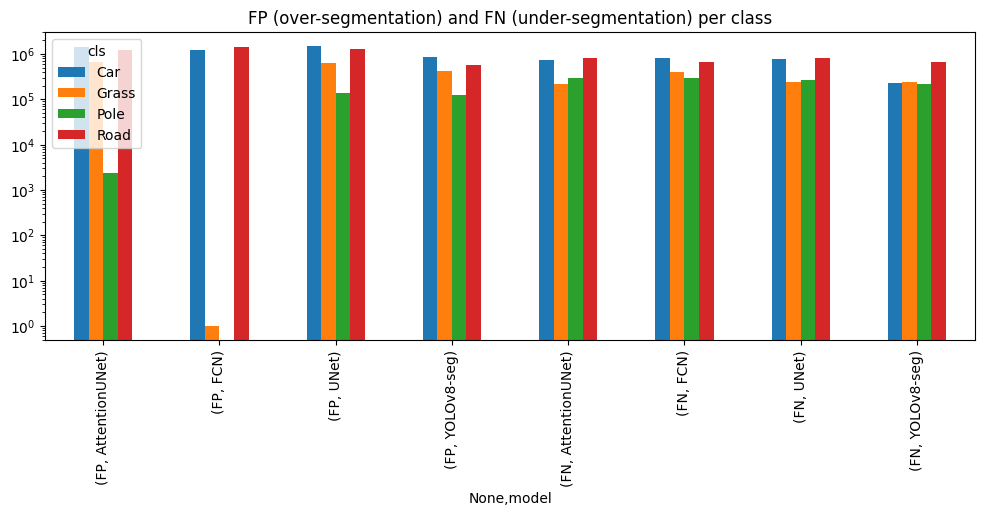

In [21]:
#Step 21
#TP, FP and FN (under-segmentation and over-segmentation)
agg = fg.groupby(["model", "cls"])[["TP", "FP", "FN"]].sum()
agg["FP/FN"] = (agg.FP / agg.FN.clip(lower=1)).round(2)
agg["tendency"] = np.where(agg["FP/FN"] > 1.2, "over-segmentation",
                  np.where(agg["FP/FN"] < 0.8, "under-segmentation", "balanced"))
print(agg)
agg.to_csv("/content/drive/MyDrive/seg_tp_fp_fn.csv")

# stacked view for the one-slide summary
ax = (agg[["FP", "FN"]].unstack(0).T.plot(kind="bar", figsize=(12, 4), logy=True))
plt.title("FP (over-segmentation) and FN (under-segmentation) per class"); plt.show()

In [22]:
#Step 22
#Hypothesis tests
wide = per_fold.pivot(index="fold", columns="model", values="dice")[ORDER]

# global test
F, p = stats.f_oneway(*[wide[m] for m in ORDER])
print(f"One-way ANOVA: F = {F:.3f}, p = {p:.4f}")

from statsmodels.stats.anova import AnovaRM
print(AnovaRM(per_fold, "dice", "fold", within=["model"]).fit())     # repeated-measures ANOVA (paired design)

# pairwise paired t-tests with Bonferroni correction
pairs = list(itertools.combinations(ORDER, 2))
rows = []
for a, b in pairs:
    t, pv = stats.ttest_rel(wide[a], wide[b])
    rows.append(dict(A=a, B=b, mean_diff=round((wide[a] - wide[b]).mean(), 4),
                     t=round(t, 6), p=round(pv, 6), p_bonferroni=round(min(1, pv * len(pairs)), 6)))
pw = pd.DataFrame(rows)
print(pw)
pw.to_csv("/content/drive/MyDrive/seg_pairwise_tests.csv", index=False)

One-way ANOVA: F = 135.442, p = 0.0000
               Anova
      F Value  Num DF  Den DF Pr > F
------------------------------------
model 132.8619 3.0000 12.0000 0.0000

               A              B  mean_diff          t         p  p_bonferroni
0            FCN           UNet    -0.1034 -25.275827  0.000015      0.000087
1            FCN  AttentionUNet    -0.0735 -12.268275  0.000254      0.001521
2            FCN     YOLOv8-seg    -0.2216 -16.569499  0.000078      0.000466
3           UNet  AttentionUNet     0.0298   8.294447  0.001154      0.006921
4           UNet     YOLOv8-seg    -0.1182  -7.228775  0.001943      0.011657
5  AttentionUNet     YOLOv8-seg    -0.1481  -9.259494  0.000756      0.004539


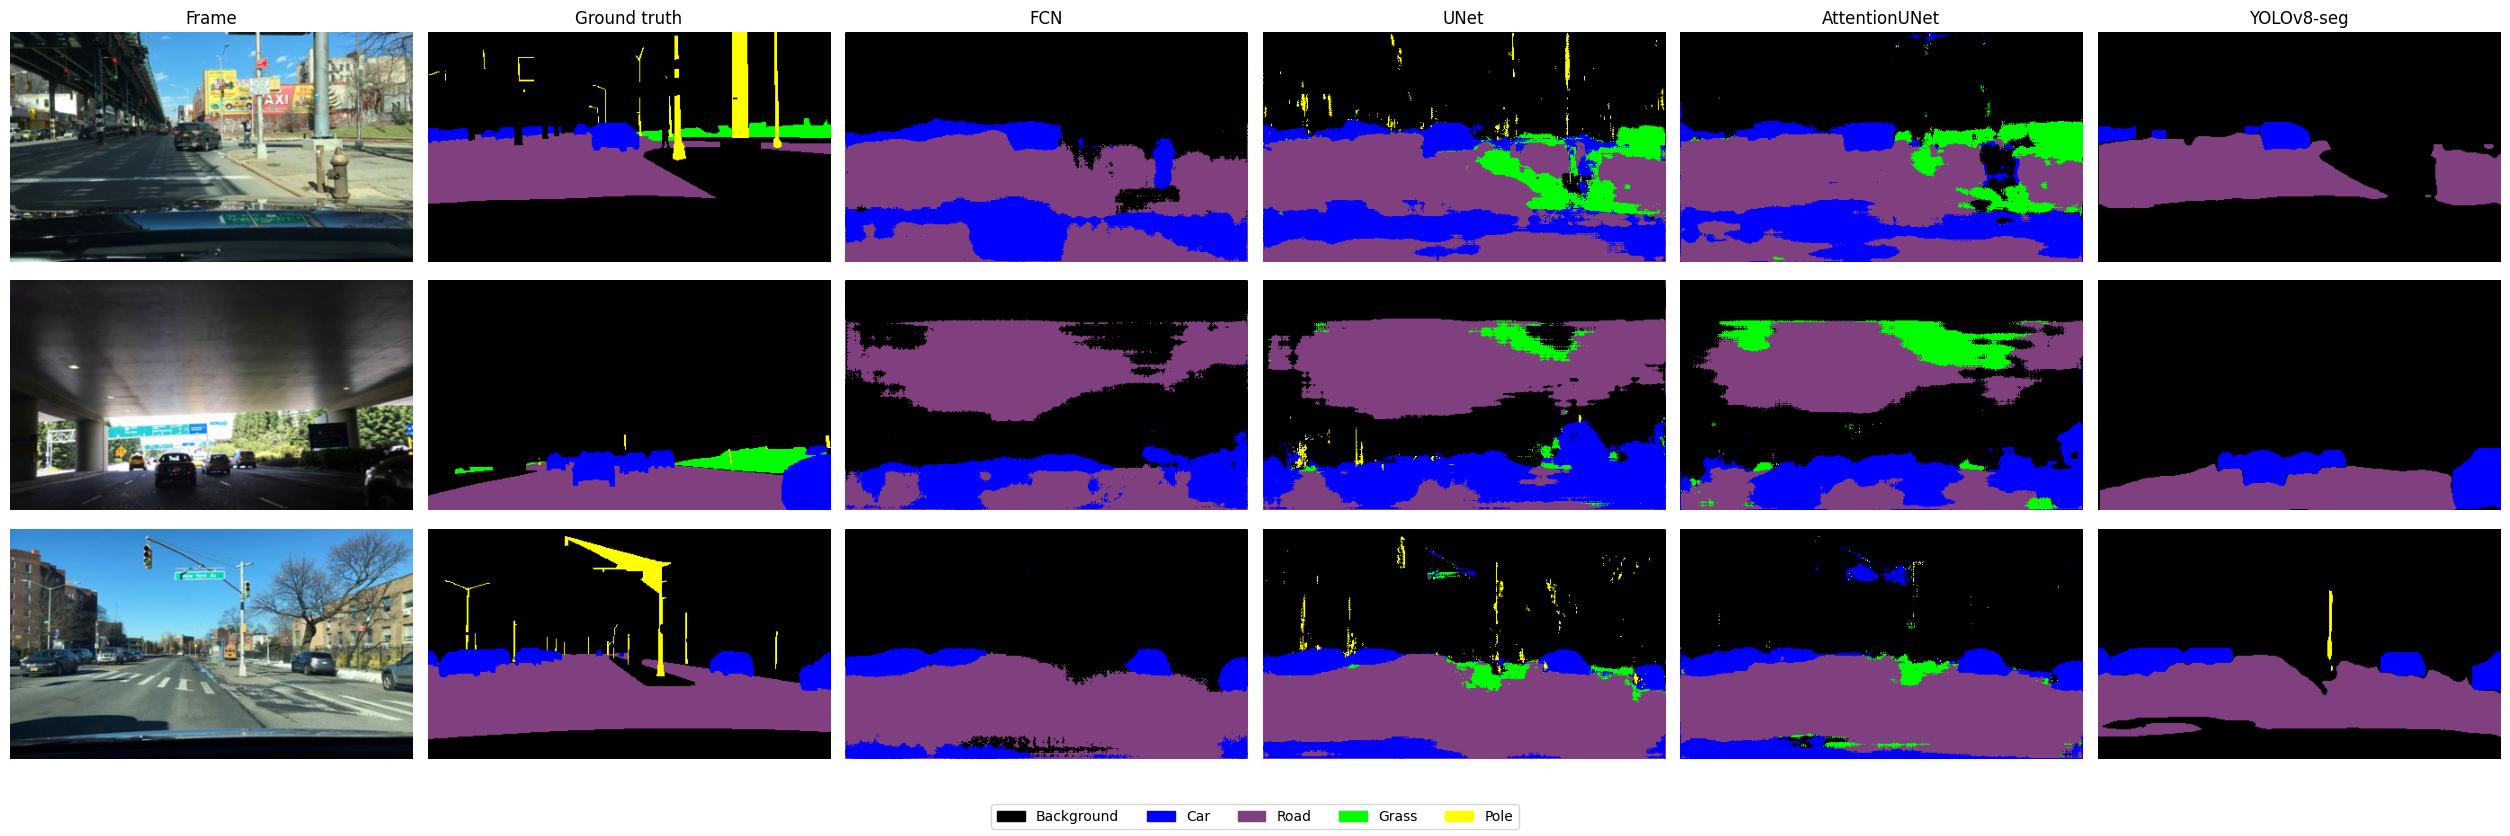

In [23]:
#Step 23: qualitative comparison on fold 0 test images
import cv2
import matplotlib.patches as mpatches
from ultralytics import YOLO
PALETTE = np.array([[0,0,0],[0,0,255],[128,64,128],[0,255,0],[255,255,0]], dtype=np.uint8)

MODEL_DIR = "/content/drive/MyDrive/seg_models"
IMGSZ  = globals().get("IMGSZ", 224)
DEVICE = globals().get("DEVICE", "cpu")

kmodels = {n: keras.models.load_model(f"{MODEL_DIR}/{n}_fold0.keras", compile=False)
           for n in ["FCN", "UNet", "AttentionUNet"]}
yp = f"{MODEL_DIR}/yolo_runs/fold0/weights/best.pt"
yolo0 = YOLO(yp) if os.path.exists(yp) else None

def load_xy(s):
    return IMG_CACHE[s].astype(np.float32) / 255.0, MSK_CACHE[s]

def yolo_semantic(model, s):
    r = next(iter(model.predict(yolo_img_path[s], imgsz=IMGSZ, conf=0.25, retina_masks=True,
                                device=DEVICE, verbose=False)))
    sem = np.zeros(r.orig_shape, np.uint8)
    if r.masks is not None:
        cls = r.boxes.cls.cpu().numpy().astype(int)
        msk = r.masks.data.cpu().numpy() > 0.5
        for c in (1, 2, 0, 3):                              # Road, Grass, Car, then Pole on top
            for i in np.where(cls == c)[0]:
                sem[msk[i]] = c + 1
    return cv2.resize(sem, (W, H), interpolation=cv2.INTER_NEAREST)

test_names = folds[3]["test"]                               # 64 images
pole = {s: int((MSK_CACHE[s] == 4).sum()) for s in test_names}
best_pole = max(pole, key=pole.get)                         # image with the most Pole pixels
chosen = [best_pole] + random.sample([s for s in test_names if s != best_pole], 2)

cols = ["Frame", "Ground truth"] + list(kmodels) + (["YOLOv8-seg"] if yolo0 else [])
fig, ax = plt.subplots(len(chosen), len(cols), figsize=(4.2 * len(cols), 2.8 * len(chosen)))
for r_i, s in enumerate(chosen):
    x, gt = load_xy(s)
    preds = [np.argmax(m.predict(x[None], verbose=0), axis=-1)[0] for m in kmodels.values()]
    if yolo0: preds.append(yolo_semantic(yolo0, s))
    ims = [x] + [PALETTE[np.where(m == IGNORE, 0, m)] for m in [gt] + preds]
    for c_i, im in enumerate(ims):
        ax[r_i, c_i].imshow(im); ax[r_i, c_i].axis("off")
        if r_i == 0: ax[r_i, c_i].set_title(cols[c_i])
fig.legend(handles=[mpatches.Patch(color=PALETTE[i] / 255, label=n)
                    for i, n in enumerate(CLASS_NAMES)], loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.05, 1, 1))
os.makedirs("/content/drive/MyDrive/seg_figures", exist_ok=True)
plt.savefig("/content/drive/MyDrive/seg_figures/07_qualitative.png", dpi=200, bbox_inches="tight")
plt.show()

In [27]:
#Step 24: loss comparison
import gc
def make_loss(kind, weights, n=5, ignore=255, gamma=2.0, a=0.3, b=0.7):
    ops = keras.ops; eps = 1e-7
    w = ops.convert_to_tensor(weights, dtype="float32")
    def loss(y_true, y_pred):
        y_true = ops.cast(y_true, "int32")
        valid  = ops.cast(y_true != ignore, "float32")
        y_safe = ops.where(y_true == ignore, 0, y_true)
        oh = ops.one_hot(y_safe, n) * valid[..., None]
        pv = y_pred * valid[..., None]
        wt = ops.take(w, y_safe) * valid
        pt = ops.sum(oh * y_pred, axis=-1)
        den = ops.sum(wt) + eps
        out = 0.0
        if kind in ("wce", "wce_dice"):
            out += ops.sum(-ops.log(pt + eps) * wt) / den
        if kind in ("focal", "focal_dice"):
            out += ops.sum(-ops.power(1 - pt, gamma) * ops.log(pt + eps) * wt) / den
        tp = ops.sum(oh * pv, axis=(0, 1, 2))
        fp = ops.sum(pv, axis=(0, 1, 2)) - tp
        fn = ops.sum(oh, axis=(0, 1, 2)) - tp
        if kind in ("dice", "wce_dice", "focal_dice"):
            out += ops.mean((1 - (2*tp + 1) / (2*tp + fp + fn + 1))[1:])
        if kind == "focal_tversky":
            out += ops.mean(ops.power(1 - (tp + 1) / (tp + a*fp + b*fn + 1), 0.75)[1:])
        return out
    return loss

LOSS_CSV = "/content/drive/MyDrive/seg_results_loss.csv"
loss_res = pd.read_csv(LOSS_CSV).to_dict("records") if os.path.exists(LOSS_CSV) else []
done_l = {(r["fold"], r["model"]) for r in loss_res}
for k in range(5):
    tr, va, te = get_loaders(k)
    for kind in ["wce", "dice", "wce_dice", "focal", "focal_dice", "focal_tversky"]:
        tag = f"UNet|{kind}"
        if (k, tag) in done_l: continue
        keras.utils.set_random_seed(SEED)
        model = BUILDERS["UNet"]()
        model.compile(optimizer=Adam(LR), loss=make_loss(kind, cw))
        model.fit(tr, validation_data=va, epochs=EPOCHS, verbose=0)      # 20 epochs
        loss_res += metrics_from_conf(evaluate_keras(model, te), tag, k)
        pd.DataFrame(loss_res).to_csv(LOSS_CSV, index=False)
        del model; keras.backend.clear_session(); gc.collect(); torch.cuda.empty_cache()

d = pd.DataFrame(loss_res); fgd = d[d.cls.isin(["Car","Road","Grass","Pole"])]
print(fgd.groupby("model")[["dice","iou"]].mean().round(3))            # mean over classes and folds
print(fgd.groupby(["model","cls"]).dice.mean().unstack().round(3))     # per-class Dice

                     dice    iou
model                           
UNet|dice           0.450  0.337
UNet|focal          0.480  0.365
UNet|focal_dice     0.461  0.346
UNet|focal_tversky  0.503  0.378
UNet|wce            0.472  0.349
UNet|wce_dice       0.467  0.346
cls                   Car  Grass   Pole   Road
model                                         
UNet|dice           0.590  0.226  0.150  0.833
UNet|focal          0.636  0.231  0.197  0.858
UNet|focal_dice     0.611  0.226  0.171  0.836
UNet|focal_tversky  0.663  0.288  0.226  0.834
UNet|wce            0.625  0.249  0.203  0.811
UNet|wce_dice       0.599  0.259  0.186  0.823


In [25]:
import cv2, gc, os, random
import numpy as np
from PIL import Image

CP_DIR = "/content/cp_frames"          # local Colab disk; extras are regenerated each run
os.makedirs(CP_DIR, exist_ok=True)
POLE_RAW, CAR_RAW = 5, 13              # raw label ids (see REMAP in Step 6)

def read_pair(s):
    """Full-resolution RGB image and RAW id mask for one frame name."""
    img = np.array(Image.open(img_map[s]).convert("RGB"))
    idm = np.array(Image.open(id_map[s]))
    return img, idm

def build_pole_bank(pool, max_bank=300, max_scan=800, min_h=40, min_area=120):
    """Cut out real poles (image crop + mask) from frames in `pool`."""
    bank = []
    for s in pool[:max_scan]:
        img, idm = read_pair(s)
        n, lab, st, _ = cv2.connectedComponentsWithStats((idm == POLE_RAW).astype(np.uint8), connectivity=8)
        for i in range(1, n):
            x, y, w, h, area = st[i]
            if h < min_h or area < min_area or h < 1.5 * w:      # keep tall, thin, pole-like pieces only
                continue
            bank.append((img[y:y+h, x:x+w].copy(), lab[y:y+h, x:x+w] == i))
            if len(bank) >= max_bank:
                return bank
    if not bank:
        raise ValueError("No pole crops found - lower min_h/min_area or scan more frames.")
    return bank

def paste_poles(img, idm, bank, rng, n_poles=3, min_new=60):
    """Paste random pole crops onto a frame. Returns (new_img, new_raw_id_mask, boxes) or None."""
    out_img, out_id = img.copy(), idm.copy()
    Hh, Ww = idm.shape
    added, boxes = 0, []
    for _ in range(n_poles):
        crop, m = rng.choice(bank)
        h, w = m.shape
        sc = min(rng.uniform(0.7, 1.3), 0.6 * Hh / h)
        nh, nw = max(8, int(h * sc)), max(2, int(w * sc))
        crop = cv2.resize(crop, (nw, nh), interpolation=cv2.INTER_LINEAR)
        m = cv2.resize(m.astype(np.uint8), (nw, nh), interpolation=cv2.INTER_NEAREST) > 0
        if rng.random() < 0.5:
            crop, m = crop[:, ::-1], m[:, ::-1]
        x0 = rng.randint(0, max(0, Ww - nw))
        y1 = rng.randint(int(0.45 * Hh), int(0.80 * Hh))          # pole base sits in the lower-middle of the frame
        y0 = max(0, y1 - nh)
        reg_id  = out_id[y0:y0 + nh, x0:x0 + nw]
        reg_img = out_img[y0:y0 + nh, x0:x0 + nw]
        allow = m & (reg_id != CAR_RAW)                          # never paint over a car
        reg_img[allow] = crop[allow]
        reg_id[allow]  = POLE_RAW
        added += int(allow.sum()); boxes.append((x0, y0, nw, nh))
    return (out_img, out_id, boxes) if added >= min_new else None

In [28]:
#Step 25: extra cut-paste frames (training split only) and ablation
def make_cp_extra(n, subset, all_names, seed=SEED + 1):
    rng = random.Random(seed)
    real = [s for s in subset if "_cp" not in s]
    outside = [s for s in all_names if s not in set(subset)]; rng.shuffle(outside)
    bank = build_pole_bank(outside); extras = {}
    while len(extras) < n:
        b = rng.choice(real)
        out = paste_poles(*read_pair(b), bank, rng, n_poles=rng.randint(2, 4))
        if out is None: continue
        s_img, s_id, _ = out; name = f"{b}_cpx{len(extras)}"
        Image.fromarray(s_img).save(f"{CP_DIR}/{name}.png"); Image.fromarray(s_id).save(f"{CP_DIR}/{name}_id.png")
        img_map[name] = f"{CP_DIR}/{name}.png"; id_map[name] = f"{CP_DIR}/{name}_id.png"
        IMG_CACHE[name], MSK_CACHE[name] = load_pair(name)
        extras[name] = b
    return extras

EXTRAS = make_cp_extra(150, SUBSET2, names)
ABL_CSV = "/content/drive/MyDrive/seg_results_cp_ablation.csv"
abl = []
for k in range(5):
    _, va, te = get_loaders(k); base = set(folds[k]["train"])
    for n_extra in (0, 40, 120):
        tr_names = folds[k]["train"] + [e for e, b in EXTRAS.items() if b in base][:n_extra]
        tr = SegSequence(tr_names, BATCH_SIZE, True)
        keras.utils.set_random_seed(SEED)
        model = BUILDERS["UNet"](); model.compile(optimizer=Adam(LR), loss=LOSS)
        model.fit(tr, validation_data=va, epochs=EPOCHS, verbose=0)
        abl += metrics_from_conf(evaluate_keras(model, te), f"UNet+cp{n_extra}", k)
        pd.DataFrame(abl).to_csv(ABL_CSV, index=False)
        del model; keras.backend.clear_session(); gc.collect(); torch.cuda.empty_cache()
a = pd.DataFrame(abl); print(a.groupby(["model","cls"]).dice.mean().unstack().round(3))

KeyboardInterrupt: 

In [10]:
!pip install -q ultralytics
import cv2, gc, pandas as pd, torch
from ultralytics import YOLO

H, W = 256, 448
IMGSZ = 448
DEVICE = 0 if torch.cuda.is_available() else "cpu"
RESULTS_CSV = "/content/drive/MyDrive/seg_results_full.csv"
MODEL_DIR   = "/content/drive/MyDrive/seg_models"

def load_mask(s):
    m = remap_mask(np.array(Image.open(id_map[s])))
    return np.asarray(Image.fromarray(m).resize((W, H), Image.NEAREST), np.uint8)

MSK_CACHE = {s: load_mask(s) for s in SUBSET2}      # labels only; images are not needed
yolo_img_path = {s: img_map[s] for s in SUBSET2}    # SAM and YOLO read the original image files directly

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [12]:
#Step 26: SAM vs YOLO
from ultralytics import SAM
sam = SAM("sam_b.pt")                      # use "mobile_sam.pt" if memory is short
def yolo_w(k):
    for p in (f"{OUT_DIR}/yolo_runs/fold{k}/weights/best.pt", f"{MODEL_DIR}/yolo_runs/fold{k}/weights/best.pt"):
        if os.path.exists(p): return p

def yolo_boxes(yo, s, top=60):
    r = next(iter(yo.predict(yolo_img_path[s], imgsz=IMGSZ, conf=0.05, device=DEVICE, verbose=False)))
    if r.boxes is None or len(r.boxes) == 0: return np.zeros((0, 4)), np.zeros(0, int)
    o = np.argsort(-r.boxes.conf.cpu().numpy())[:top]
    return r.boxes.xyxy.cpu().numpy()[o], r.boxes.cls.cpu().numpy().astype(int)[o]

def gt_boxes(s):
    m = MSK_CACHE[s]; ow, oh = Image.open(img_map[s]).size; sx, sy = ow / W, oh / H
    B, C = [], []
    for c in (1, 2, 3, 4):
        n, lab, st, _ = cv2.connectedComponentsWithStats((m == c).astype(np.uint8), connectivity=8)
        for i in range(1, n):
            x, y, bw, bh, ar = st[i]
            if ar >= 4: B.append([x*sx, y*sy, (x+bw)*sx, (y+bh)*sy]); C.append(c - 1)
    return np.array(B, np.float32).reshape(-1, 4), np.array(C, int)

SAM_FALLBACK = 0

def sam_masks(path, boxes):
    """One mask per box, in the same order as `boxes` (None if SAM gives no mask for a box)."""
    global SAM_FALLBACK
    boxes = np.asarray(boxes, np.float32).reshape(-1, 4)
    r = sam.predict(path, bboxes=boxes.tolist(), verbose=False)[0]
    if r.masks is not None and len(r.masks.data) == len(boxes):
        m = r.masks.data.cpu().numpy() > 0.5
        return [m[i] for i in range(len(boxes))]
    SAM_FALLBACK += 1                      # count mismatch: redo one box at a time so boxes and masks stay aligned
    out = []
    for b in boxes:
        r = sam.predict(path, bboxes=[b.tolist()], verbose=False)[0]
        out.append(r.masks.data[0].cpu().numpy() > 0.5 if r.masks is not None and len(r.masks.data) else None)
    return out

def sam_semantic(s, boxes, cls):
    sem = np.zeros((H, W), np.uint8)
    if len(boxes) == 0: return sem
    msk = sam_masks(yolo_img_path[s], boxes)
    for c in (1, 2, 0, 3):                                    # Road, Grass, Car, then Pole on top
        for i in np.where(np.asarray(cls) == c)[0]:
            if msk[i] is not None:
                sem[cv2.resize(msk[i].astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST) > 0] = c + 1
    return sem

rows = []
for k in range(5):
    yo = YOLO(yolo_w(k)); cg = np.zeros((5, 5), np.int64); cy = cg.copy()
    for s in folds[k]["test"]:
        b, c = gt_boxes(s);       cg += confusion(MSK_CACHE[s], sam_semantic(s, b, c))
        b, c = yolo_boxes(yo, s); cy += confusion(MSK_CACHE[s], sam_semantic(s, b, c))
    rows += metrics_from_conf(cg, "SAM+GTbox", k) + metrics_from_conf(cy, "SAM+YOLObox", k)
    print("fold", k, "done")
res = pd.read_csv(RESULTS_CSV); res = res[~res.model.isin(["SAM+GTbox", "SAM+YOLObox"])]
pd.concat([res, pd.DataFrame(rows)]).to_csv(RESULTS_CSV, index=False)
del sam; gc.collect(); torch.cuda.empty_cache()

fold 0 done


FileNotFoundError: 'None' does not exist

In [ ]:
rows = []
for k in range(5):
    wpath = yolo_w(k); yo = YOLO(wpath) if wpath else None
    cg = np.zeros((5, 5), np.int64); cy = cg.copy()
    for s in folds[k]["test"]:
        b, c = gt_boxes(s); cg += confusion(MSK_CACHE[s], sam_semantic(s, b, c))
        if yo is not None:
            b, c = yolo_boxes(yo, s); cy += confusion(MSK_CACHE[s], sam_semantic(s, b, c))
    rows += metrics_from_conf(cg, "SAM+GTbox", k)
    if yo is not None: rows += metrics_from_conf(cy, "SAM+YOLObox", k)
    print("fold", k, "done" if yo is not None else "done (YOLO weights missing: GT boxes only)")

In [ ]:
#Step 26b: bounding boxes (GT vs YOLO) and the SAM masks they give
import matplotlib.patches as patches
import matplotlib.pyplot as plt
from ultralytics import SAM
if "sam" not in globals(): sam = SAM("sam_b.pt")      # Step 26 deletes SAM at its end

K = 0                                                  # fold to show (needs its YOLO weights)
BOX_NAMES = ["Car", "Road", "Grass", "Pole"]
BOX_COL   = ["#1f3bff", "#8a2be2", "#16a34a", "#f59e0b"]
PAL = np.array([[0,0,0],[0,0,255],[128,64,128],[0,255,0],[255,255,0]], np.uint8)
SHOW_CONF, SHOW_TOP = 0.25, 25          # display only; the evaluation in Step 26 uses conf 0.05 and 60 boxes

def yolo_boxes_conf(yo, s):
    r = next(iter(yo.predict(yolo_img_path[s], imgsz=IMGSZ, conf=SHOW_CONF, device=DEVICE, verbose=False)))
    if r.boxes is None or len(r.boxes) == 0: return np.zeros((0, 4)), np.zeros(0, int), np.zeros(0)
    o = np.argsort(-r.boxes.conf.cpu().numpy())[:SHOW_TOP]
    return r.boxes.xyxy.cpu().numpy()[o], r.boxes.cls.cpu().numpy().astype(int)[o], r.boxes.conf.cpu().numpy()[o]

def draw_boxes(ax, img, boxes, cls, scores=None, title=""):
    ax.imshow(img); ax.axis("off"); ax.set_title(title, fontsize=12)
    for i, (b, c) in enumerate(zip(boxes, cls)):
        x1, y1, x2, y2 = b
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=BOX_COL[c], lw=2))
        lab = BOX_NAMES[c] + (f" {scores[i]:.2f}" if scores is not None else "")
        inside = y1 < 18                                           # put the label inside if the box touches the top
        ax.text(x1 + 2, y1 + 3 if inside else y1 - 3, lab, color="white", fontsize=8,
                va="top" if inside else "bottom", bbox=dict(fc=BOX_COL[c], ec="none", pad=1.2))

def overlay(s, sem):
    small = np.asarray(Image.open(img_map[s]).convert("RGB").resize((W, H), Image.BILINEAR)).astype(np.float32)
    m = sem > 0; out = small.copy()
    out[m] = 0.45 * small[m] + 0.55 * PAL[sem][m]
    return out.astype(np.uint8)

yo = YOLO(yolo_w(K))
test = folds[K]["test"]
pole_px = {s: int((MSK_CACHE[s] == 4).sum()) for s in test}
pick = [max(test, key=pole_px.get)] + random.Random(SEED).sample([s for s in test if s != max(test, key=pole_px.get)], 2)

fig, ax = plt.subplots(len(pick), 4, figsize=(24, 4.4 * len(pick)))
for r, s in enumerate(pick):
    img = Image.open(img_map[s]).convert("RGB")
    gb, gc_ = gt_boxes(s)
    yb, yc, ys = yolo_boxes_conf(yo, s)
    draw_boxes(ax[r, 0], img, gb, gc_, None, f"GT boxes ({len(gb)})")
    ax[r, 1].imshow(overlay(s, sam_semantic(s, gb, gc_))); ax[r, 1].axis("off"); ax[r, 1].set_title("SAM masks from GT boxes")
    draw_boxes(ax[r, 2], img, yb, yc, ys, f"YOLO boxes ({len(yb)}, conf >= {SHOW_CONF})")
    ax[r, 3].imshow(overlay(s, sam_semantic(s, yb, yc))); ax[r, 3].axis("off"); ax[r, 3].set_title("SAM masks from YOLO boxes")
fig.legend(handles=[patches.Patch(color=BOX_COL[i], label=BOX_NAMES[i]) for i in range(4)], loc="lower center", ncol=4, fontsize=13)
plt.tight_layout(rect=[0, 0.03, 1, 1])
os.makedirs("/content/drive/MyDrive/seg_figures", exist_ok=True)
plt.savefig("/content/drive/MyDrive/seg_figures/sam_boxes_gt_vs_yolo.png", dpi=150); plt.show()

In [30]:
#Step 27: probability fusion of Attention U-Net and YOLO
def yolo_prob(yo, s):
    r = next(iter(yo.predict(yolo_img_path[s], imgsz=IMGSZ, conf=0.05, retina_masks=True, device=DEVICE, verbose=False)))
    P = np.zeros((H, W, 5), np.float32)
    if r.masks is not None:
        cls = r.boxes.cls.cpu().numpy().astype(int); cf = r.boxes.conf.cpu().numpy()
        msk = r.masks.data.cpu().numpy() > 0.5
        for i in range(len(cls)):
            m = cv2.resize(msk[i].astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST) > 0
            P[m, cls[i] + 1] = np.maximum(P[m, cls[i] + 1], cf[i])
    P[..., 0] = np.clip(1 - P[..., 1:].max(-1), 0, 1)
    return P / P.sum(-1, keepdims=True)

def collect(k, split, att, yo):
    nm = folds[k][split]
    Pa = np.stack([att.predict(IMG_CACHE[s][None].astype(np.float32) / 255, verbose=0)[0] for s in nm]).astype(np.float16)
    Py = np.stack([yolo_prob(yo, s) for s in nm]).astype(np.float16)
    return Pa, Py, np.stack([MSK_CACHE[s] for s in nm])

def fused_conf(Pa, Py, Y, w):
    w = np.asarray(w, np.float32)
    return confusion(Y, ((1 - w) * Pa.astype(np.float32) + w * Py.astype(np.float32)).argmax(-1))

def fg_dice(conf):
    tp = np.diag(conf); return np.mean((2*tp / (conf.sum(0) + conf.sum(1) + 1e-9))[1:])

def tune_w(Pa, Py, Y, grid=(0, .25, .5, .75, 1), sweeps=2):
    w = np.zeros(5, np.float32); best = fg_dice(fused_conf(Pa, Py, Y, w))
    for _ in range(sweeps):
        for c in range(5):
            for g in grid:
                w2 = w.copy(); w2[c] = g; sc = fg_dice(fused_conf(Pa, Py, Y, w2))
                if sc > best: best, w = sc, w2
    return w

rows = []
for k in range(5):
    p = f"{MODEL_DIR}/AttentionUNet_fold{k}.keras"
    if not os.path.exists(p): print("fold", k, "missing, skipped"); continue
    att = keras.models.load_model(p, compile=False); yo = YOLO(yolo_w(k))
    w = tune_w(*collect(k, "val", att, yo))                               # tuned on validation only
    Pa, Py, Y = collect(k, "test", att, yo)
    rows += metrics_from_conf(fused_conf(Pa, Py, Y, w), "AttUNet+YOLO", k)
    print("fold", k, "weights (Bg, Car, Road, Grass, Pole):", w)
    del att, yo, Pa, Py; keras.backend.clear_session(); gc.collect(); torch.cuda.empty_cache()
res = pd.read_csv(RESULTS_CSV); res = res[res.model != "AttUNet+YOLO"]
pd.concat([res, pd.DataFrame(rows)]).to_csv(RESULTS_CSV, index=False)

fold 0 weights (Bg, Car, Road, Grass, Pole): [       0.25           1           1        0.25           1]
fold 1 missing, skipped
fold 2 missing, skipped
fold 3 missing, skipped
fold 4 missing, skipped



=== Main comparison ===


cls,Car,Road,Grass,Pole,mean_Dice,mean_IoU,fold_std,n_folds
model,,,,,,,,
SAM+GTbox,0.847,0.931,0.742,0.732,0.813,0.694,0.021,5
YOLOv8-seg,0.842,0.917,0.347,0.347,0.613,0.499,0.027,5
SAM+YOLObox,0.769,0.865,0.331,0.364,0.582,0.453,0.037,5
AttUNet+YOLO,0.872,0.936,0.265,0.009,0.521,0.453,NaN,1
UNet,0.678,0.866,0.280,0.155,0.495,0.381,0.014,5
AttentionUNet,0.688,0.867,0.293,0.014,0.465,0.367,0.018,5
FCN,0.699,0.867,0.000,0.000,0.392,0.326,0.005,5


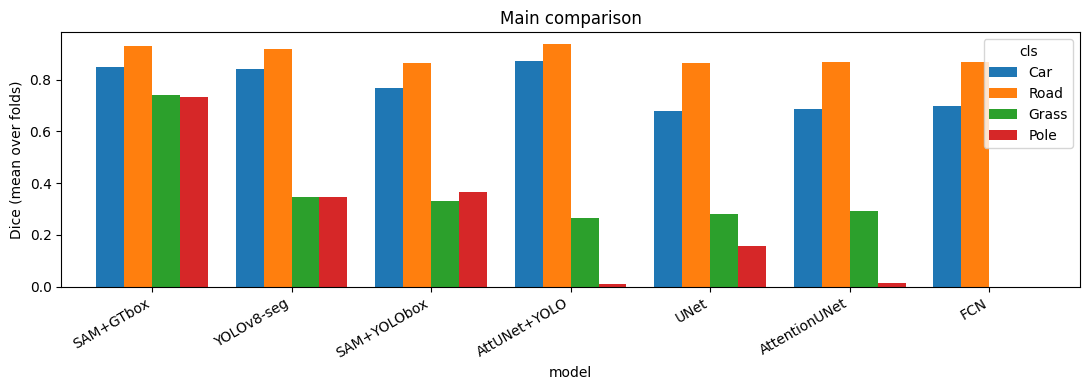


=== Loss functions ===


cls,Car,Road,Grass,Pole,mean_Dice,mean_IoU,fold_std,n_folds
model,,,,,,,,
UNet|focal_tversky,0.663,0.834,0.288,0.226,0.503,0.378,0.034,5
UNet|focal,0.636,0.858,0.231,0.197,0.480,0.365,0.018,5
UNet|wce,0.625,0.811,0.249,0.203,0.472,0.349,0.021,5
UNet|wce_dice,0.599,0.823,0.259,0.186,0.467,0.346,0.043,5
UNet|focal_dice,0.611,0.836,0.226,0.171,0.461,0.346,0.022,5
UNet|dice,0.590,0.833,0.226,0.150,0.450,0.337,0.046,5


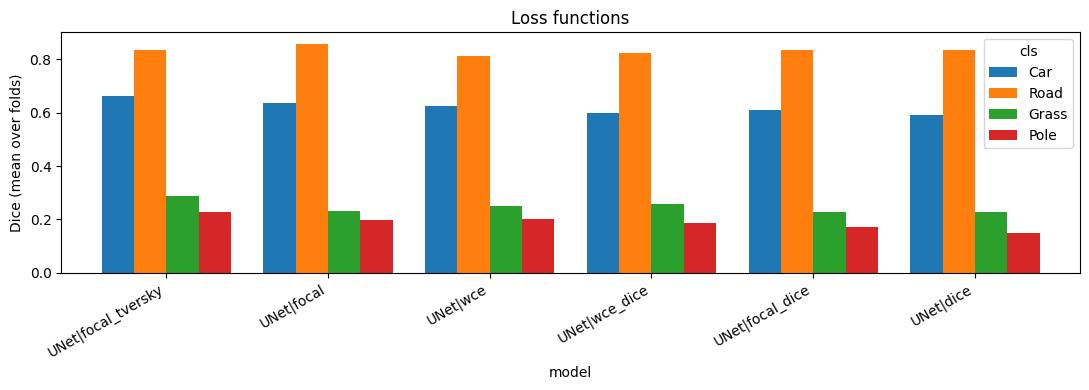


=== Cut-paste ablation ===


cls,Car,Road,Grass,Pole,mean_Dice,mean_IoU,fold_std,n_folds
model,,,,,,,,
UNet+cp120,0.590,0.806,0.189,0.200,0.446,0.328,0.030,4
UNet+cp40,0.559,0.798,0.196,0.138,0.422,0.309,0.016,4
UNet+cp0,0.484,0.778,0.180,0.085,0.382,0.277,0.052,4


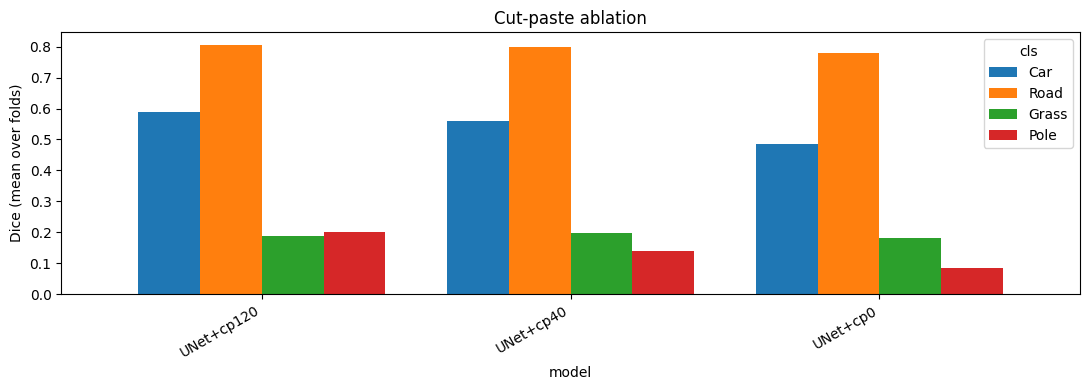

In [31]:
#Step 28: final summary tables and chart
FG = ["Car", "Road", "Grass", "Pole"]
files = {"Main comparison": RESULTS_CSV,
         "Loss functions": "/content/drive/MyDrive/seg_results_loss.csv",
         "Cut-paste ablation": "/content/drive/MyDrive/seg_results_cp_ablation.csv"}
os.makedirs("/content/drive/MyDrive/seg_figures", exist_ok=True)

for title, path in files.items():
    if not os.path.exists(path): print(title, ": file missing, skipped"); continue
    d = pd.read_csv(path); f = d[d.cls.isin(FG)]
    t = f.pivot_table(index="model", columns="cls", values="dice", aggfunc="mean")[FG]
    t["mean_Dice"] = t.mean(axis=1)
    t["mean_IoU"]  = f.groupby("model").iou.mean()
    pf = f.groupby(["model", "fold"]).dice.mean().groupby("model").agg(["mean", "std"])
    t["fold_std"]  = pf["std"]                      # variation across the 5 folds
    t["n_folds"]   = d.groupby("model").fold.nunique()
    t = t.sort_values("mean_Dice", ascending=False).round(3)
    print(f"\n=== {title} ==="); display(t)
    t.to_csv(f"/content/drive/MyDrive/seg_figures/{title.replace(' ', '_')}.csv")
    ax = t[FG].plot(kind="bar", figsize=(11, 4), width=0.8)
    ax.set_ylabel("Dice (mean over folds)"); ax.set_title(title); plt.xticks(rotation=30, ha="right")
    plt.tight_layout(); plt.savefig(f"/content/drive/MyDrive/seg_figures/{title.replace(' ', '_')}.png", dpi=150); plt.show()

fusion weights: [       0.25           1           1        0.25           1]


100%|██████████| 64/64 [01:33<00:00,  1.46s/it]


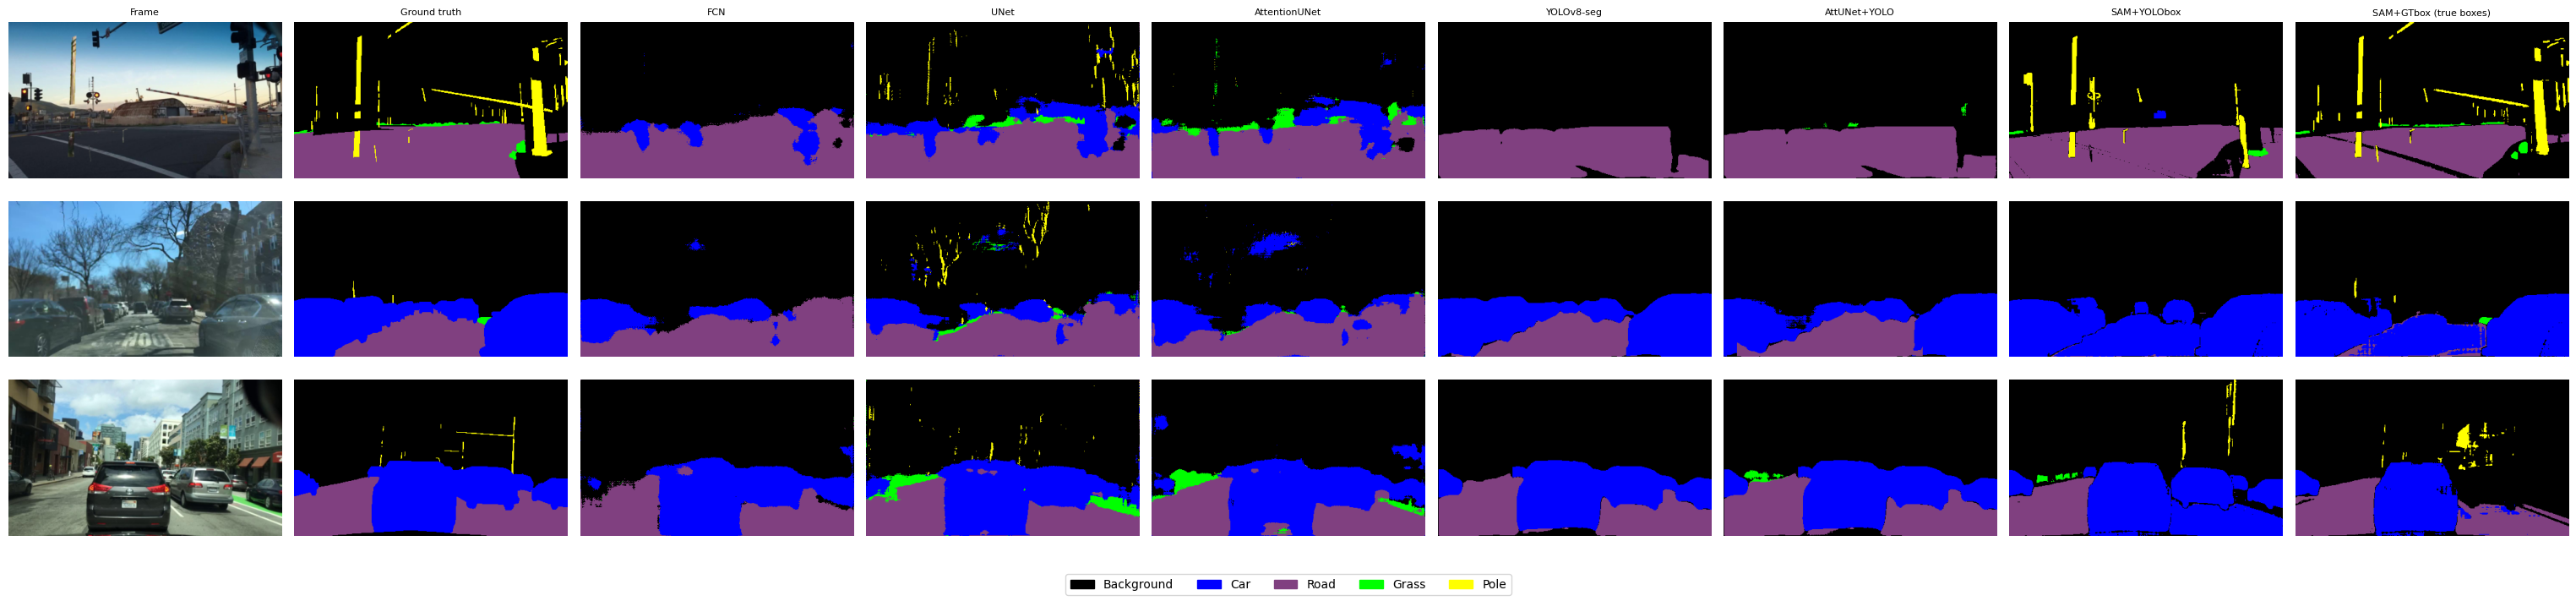

In [32]:
#Step 28: predictions from every model on the fold-0 test images
from ultralytics import SAM
sam = SAM("sam_b.pt")                          # Step 26 deleted it, so reload

K = 0                                          # only fold 0 has saved models
test_names = folds[K]["test"]                  # images none of these models trained on
SAVE_DIR = "/content/drive/MyDrive/seg_predictions"

kmodels = {n: keras.models.load_model(f"{MODEL_DIR}/{n}_fold{K}.keras", compile=False)
           for n in ["FCN", "UNet", "AttentionUNet"]}
att = kmodels["AttentionUNet"]; yo = YOLO(yolo_w(K))
w_fuse = tune_w(*collect(K, "val", att, yo))   # fusion weights tuned on validation only, as in Step 27
print("fusion weights:", w_fuse)

def predict_all(s):
    x = IMG_CACHE[s].astype(np.float32) / 255.0
    out = {n: np.argmax(m.predict(x[None], verbose=0), axis=-1)[0].astype(np.uint8) for n, m in kmodels.items()}
    out["YOLOv8-seg"] = yolo_semantic(yo, s)
    pa = att.predict(x[None], verbose=0)[0]
    out["AttUNet+YOLO"] = ((1 - w_fuse) * pa + w_fuse * yolo_prob(yo, s)).argmax(-1).astype(np.uint8)
    b, c = yolo_boxes(yo, s); out["SAM+YOLObox"] = sam_semantic(s, b, c)
    b, c = gt_boxes(s);       out["SAM+GTbox (true boxes)"] = sam_semantic(s, b, c)
    return out

preds = {}
for s in tqdm(test_names):
    preds[s] = predict_all(s)
    for n, m in preds[s].items():              # saved as class ids 0-4 (Background, Car, Road, Grass, Pole)
        d = f"{SAVE_DIR}/{n.split(' ')[0].replace('+', '_')}"; os.makedirs(d, exist_ok=True)
        Image.fromarray(m).save(f"{d}/{s}.png")

# comparison figure: the image with the most poles plus 2 random ones
pole = {s: int((MSK_CACHE[s] == 4).sum()) for s in test_names}
best = max(pole, key=pole.get)
chosen = [best] + random.sample([s for s in test_names if s != best], 2)
cols = ["Frame", "Ground truth"] + list(preds[chosen[0]])
fig, ax = plt.subplots(len(chosen), len(cols), figsize=(3.4 * len(cols), 2.4 * len(chosen)))
for r_i, s in enumerate(chosen):
    ims = [IMG_CACHE[s]] + [PALETTE[np.where(m == IGNORE, 0, m)] for m in [MSK_CACHE[s]] + list(preds[s].values())]
    for c_i, im in enumerate(ims):
        ax[r_i, c_i].imshow(im); ax[r_i, c_i].axis("off")
        if r_i == 0: ax[r_i, c_i].set_title(cols[c_i], fontsize=8)
fig.legend(handles=[mpatches.Patch(color=PALETTE[i] / 255, label=n) for i, n in enumerate(CLASS_NAMES)],
           loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig("/content/drive/MyDrive/seg_figures/08_all_models.png", dpi=200, bbox_inches="tight"); plt.show()
del sam; gc.collect(); torch.cuda.empty_cache()